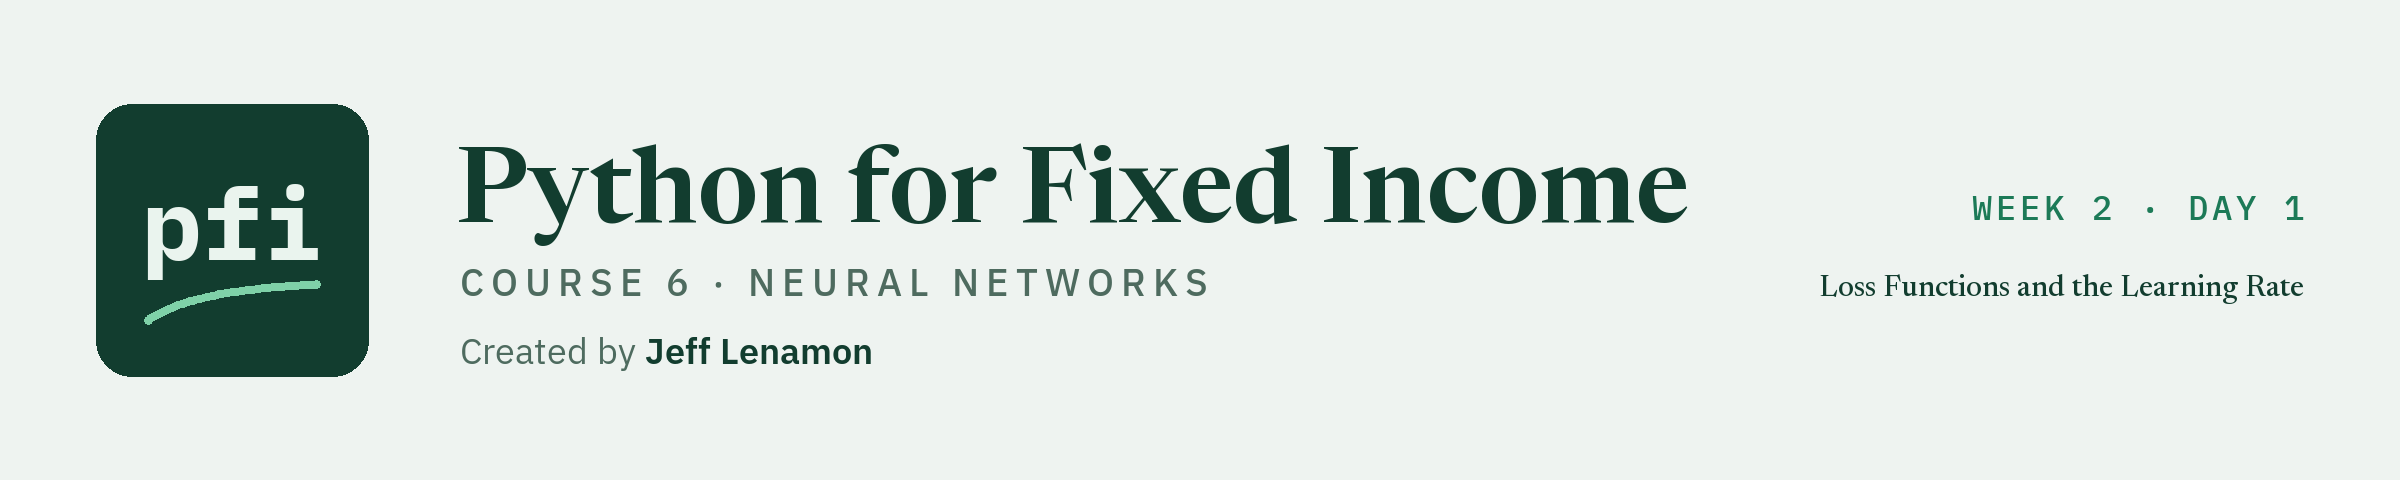

# Loss Functions and the Learning Rate

Week 2, Day 1. Week 2 is about training, and it starts with a number instead of a class: the log spread of a bond. Today: a network with a linear output is a linear regression, three losses and what each does to a large miss, a target in standard units, and the learning rate, from too small to too large.

**Data:** `benchmark.csv` and `ratings.csv`, 821 bonds of invented issuers: **synthetic**, made for this course by `tools/make_holdings.py`. No real issuer, price, or spread.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course6_neural_networks/week2/day1/06_loss_functions_and_the_learning_rate.ipynb)

Week 1 fitted networks to the card file, where the output is a probability and the loss is the log loss. Week 2 is about the fitting itself: the loss, the learning rate, the optimizer, the starting weights, and what stops a network fitting noise. Today it does that on a regression, the course's benchmark bonds, where you know the answer a straight line gives: Course 4 fitted OLS to these bonds, and Course 5 day 5 compared it with trees and forests.

**The benchmark rules, as on every benchmark day.**

* **The bonds are synthetic.** `benchmark.csv` holds 821 bonds of invented issuers, and their spreads were made by the course's generator, `tools/make_holdings.py` (read in this course, never run). Nothing here describes a real issuer, a real price, or a real market.
* **Course 4's split, rebuilt.** Course 4 split the bonds 75/25 and reported on its 206 test bonds every day of its week 1. By the test-row rule (day 1, section 1.2), Course 6 never scores them: `ensemblekit.course4_bench_rows` returns only the 615 training bonds, and every number today comes from inside them.
* **A model's output is described.** A fitted value is the network's spread for a bond with these characteristics, and a residual is the part of a bond's spread the model misses. Neither is a fair value, and no output here says a bond is cheap or rich.

Today you will:

1. Show that a `Dense(1)` output with no activation, fitted with the mean squared error, is Course 4's OLS.
2. Write `regression_losses` and compare MSE, MAE, and the Huber loss on the same fitted values, above all on the largest misses.
3. Standardize the target, see why it matters, and turn every fitted value back before it is reported.
4. Watch the learning rate of plain gradient descent go from too small to too large on one fold.
5. Write `cv_regressor` and score three networks against OLS by the same five folds, in bp.
6. Say, fold by fold, what the comparison supports.

Q. Set up today's work folder: TensorFlow's settings, the thread settings, the seed, the benchmark files, and the modules as day 5 left them.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [ ]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course6_neural_networks/requirements.txt
NEEDED = {
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

17 packages checked, all present


In [1]:
# today's setup: the TensorFlow and thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# TensorFlow writes start-up notices to stderr: these three lines must run before TensorFlow is imported
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, TensorFlow, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("statsmodels", "statsmodels"), ("scipy", "scipy"), ("tensorflow", "tensorflow"), ("keras", "keras"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# one thread for TensorFlow too, set before TensorFlow runs anything
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
# TensorFlow's own Python notices are turned down to errors; on Windows the one it writes is that it has no GPU
# support there (day 1 explains it)
tf.get_logger().setLevel("ERROR")
# where TensorFlow has a deterministic version of an operation, use it
tf.config.experimental.enable_op_determinism()

# the versions the saved outputs of this notebook came from (course6_neural_networks/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "tensorflow": "2.21.0", "keras": "3.15.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42
# Keras's seed sets Python's, numpy's, and TensorFlow's random generators at once
keras.utils.set_random_seed(SEED)

# the kinds of device TensorFlow can use on this machine
devices = sorted({device.device_type for device in tf.config.list_physical_devices()})
print(f"Devices TensorFlow can use: {', '.join(devices)}")

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "credit_card_default.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course6_06_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["benchmark.csv", "ratings.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, tensorflow 2.21.0, keras 3.15.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Devices TensorFlow can use: CPU
Work folder: pfi_course6_06_iabxynd0, in your temp folder
Data files from the data folder of the course repo: benchmark.csv, ratings.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, and `ensemblekit.py`, Course 5's complete module, both unchanged. `netkit` imports them.

In [2]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [3]:
%%writefile ensemblekit.py
"""ensemblekit: the pieces of ensembles, tuning, and rare-event modelling that the libraries leave to the analyst,
written down and tested.

Written day by day in Python for Fixed Income, Course 5: Advanced Machine Learning. It imports mlkit (Course 4's
module) and never changes it.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 5 never scores a row that Course 4 used as a test row. The course4_*_rows functions rebuild Course 4's
  splits exactly and return only the rows Course 5 may use; the closed rows are never returned.
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart.
- Every library call that can use more than one thread is given n_jobs=1, so every run gives the same digits.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from sklearn.model_selection import train_test_split  # Course 4's split, rebuilt

import mlkit  # Course 4's module: thresholds, metrics, splitters, and the no-leak check

# the card file: its outcome column and the 19 model columns (the four person columns are never features)
CARD_TARGET = "default payment next month"
CARD_FEATURES = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + \
    [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]


def course4_card_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's 60/20/20 split of the card file, rebuilt, without its test rows.

    Input: frame, the 30,000 accounts of credit_card_default.csv as read by pd.read_csv.
    Output: X_train (18,000 rows), X_valid (6,000 rows), y_train, y_valid, with the 19 model columns in
    CARD_FEATURES and the file's row labels. Course 4's 6,000 test rows are never returned.
    Convention: the same two calls as Course 4: train_test_split(test_size=0.2, stratify=y, random_state=42), then
    the remaining 80 percent split with test_size=0.25, stratified, same seed. The validation rows were used in
    Course 4 to choose a threshold and a pruning level, never to fit.
    Raises ValueError if a column is missing or the frame does not have 30,000 rows.
    """
    # check the frame is the whole card file
    missing = [name for name in CARD_FEATURES + [CARD_TARGET] if name not in frame.columns]
    if missing:
        raise ValueError(f"frame lacks the columns {missing}")
    if len(frame) != 30_000:
        raise ValueError(f"frame must hold the 30,000 card accounts, not {len(frame)}")
    X, y = frame[CARD_FEATURES], frame[CARD_TARGET]
    # Course 4's first cut puts 20 percent aside as test rows: they are dropped here, never returned
    X_rest, _, y_rest, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    # Course 4's second cut: a quarter of the rest (20 percent of the file) as validation rows
    X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest,
                                                          random_state=42)
    mlkit.assert_disjoint(X_train.index, X_valid.index)
    return X_train, X_valid, y_train, y_valid


def bootstrap_positions(n_rows: int, seed: int = 42) -> np.ndarray:
    """Draw n_rows row positions with replacement: one bootstrap sample.

    Input: n_rows, how many rows the data has (at least 1); seed, the random seed.
    Output: an array of n_rows positions from 0 to n_rows - 1, in the order drawn. A position can appear more than
    once, and some positions do not appear at all (about 36.8 percent of them for large n_rows).
    Convention: np.random.default_rng(seed).integers(0, n_rows, n_rows), so the same seed gives the same sample.
    Excel: =RANDBETWEEN(1,n) draws one position but takes no seed and changes at every recalculation.
    Raises ValueError if n_rows is below 1.
    """
    if n_rows < 1:
        raise ValueError(f"n_rows must be at least 1, not {n_rows}")
    # one generator per call, seeded, so the draw does not depend on anything drawn before
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_rows, n_rows)


def out_of_bag(n_rows: int, drawn: np.ndarray) -> np.ndarray:
    """The positions a bootstrap sample never drew: its out-of-bag rows.

    Inputs: n_rows, how many rows the data has; drawn, the positions of a bootstrap sample.
    Output: the sorted positions from 0 to n_rows - 1 that are not in drawn.
    Convention: a model fitted on the drawn rows has never seen these rows, so they can score it.
    Raises ValueError if drawn is empty or holds a position outside 0 to n_rows - 1.
    """
    positions = np.asarray(drawn)
    if positions.size == 0:
        raise ValueError("drawn is empty")
    if positions.min() < 0 or positions.max() > n_rows - 1:
        raise ValueError(f"drawn holds a position outside 0 to {n_rows - 1}")
    # every position, minus the ones drawn at least once
    return np.setdiff1d(np.arange(n_rows), positions)


from sklearn.metrics import roc_auc_score  # ranking quality from probabilities


def bagged_proba(bagging, X: pd.DataFrame) -> np.ndarray:
    """Bagging by hand: the average of each fitted tree's class-1 probability, each on its own columns.

    Inputs: bagging, a fitted BaggingClassifier; X, the rows to score, with the columns it was fitted on.
    Output: one number per row, the mean over bagging.estimators_ of each tree's class-1 probability on the
    columns listed in bagging.estimators_features_. It equals bagging.predict_proba(X)[:, 1] within 1e-12.
    Convention: a tree whose bootstrap sample held only one class gives 0 for class 1 when that class is 0.
    Excel: with each tree's column of outputs pasted side by side, =AVERAGE(B2:K2) filled down.
    Raises ValueError if bagging is not fitted.
    """
    if not hasattr(bagging, "estimators_"):
        raise ValueError("bagging is not fitted: call fit first")
    # the trees were fitted on plain arrays of the chosen columns, so score them the same way
    values = np.asarray(X, dtype=float)
    total = np.zeros(len(values))
    for tree, columns in zip(bagging.estimators_, bagging.estimators_features_):
        proba = tree.predict_proba(values[:, columns])
        # the tree's classes are positions in bagging.classes_; class 1 is position 1
        position = np.flatnonzero(tree.classes_ == 1)
        total += proba[:, position[0]] if position.size else 0.0
    return total / len(bagging.estimators_)


def oob_auc(model, y_train) -> float:
    """ROC AUC of the out-of-bag probabilities of a bagged model or a random forest.

    Inputs: model, fitted with oob_score=True on the training rows; y_train, those rows' outcomes, in order.
    Output: roc_auc_score(y_train, model.oob_decision_function_[:, 1]): each row scored only by the trees that
    did not draw it.
    Convention: model.oob_score_ is the accuracy of the out-of-bag votes for a classifier, not ROC AUC; this
    function gives the ranking number the course compares models by.
    Raises ValueError if the model was fitted without oob_score=True, or if a row has no out-of-bag vote (too few
    trees, so some row was drawn by every tree).
    """
    if not hasattr(model, "oob_decision_function_"):
        raise ValueError("the model has no out-of-bag outputs: fit it with oob_score=True")
    proba = model.oob_decision_function_[:, 1]
    if np.isnan(proba).any():
        raise ValueError(f"{int(np.isnan(proba).sum())} rows have no out-of-bag vote: use more trees")
    return float(roc_auc_score(y_train, proba))


def tree_correlation(forest, X: pd.DataFrame) -> float:
    """How much the trees of an ensemble agree: the mean pairwise correlation of their class-1 outputs.

    Inputs: forest, a fitted random forest, extra-trees, or bagging model (anything with estimators_, and
    estimators_features_ for bagging); X, the rows to score (validation rows).
    Output: the mean of the upper triangle of np.corrcoef over the trees' class-1 probabilities on X: 1 means
    every tree gives the same ranking, 0 means no linear agreement.
    Convention: averaging trees removes less noise the more they agree; a random forest tries a random subset of
    columns at each split to lower this number.
    Excel: =CORREL(B2:B6001,C2:C6001) for one pair of pasted tree columns.
    Raises ValueError if the ensemble has fewer than two trees.
    """
    trees = list(forest.estimators_)
    if len(trees) < 2:
        raise ValueError(f"need at least two trees, the ensemble has {len(trees)}")
    # each tree was fitted on a plain array; bagging may give each tree its own columns
    values = np.asarray(X, dtype=float)
    columns = getattr(forest, "estimators_features_", [slice(None)] * len(trees))
    outputs = np.array([tree.predict_proba(values[:, cols])[:, -1] for tree, cols in zip(trees, columns)])
    # the correlation of every pair of trees, then the mean above the diagonal
    matrix = np.corrcoef(outputs)
    return float(matrix[np.triu_indices(len(trees), k=1)].mean())


from sklearn.inspection import permutation_importance  # the drop in a score when one column is shuffled


def importance_table(model, X_valid: pd.DataFrame, y_valid, scoring: str = "roc_auc", n_repeats: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    """Two importance measures side by side: impurity importance and permutation importance.

    Inputs: model, a fitted tree ensemble with feature_importances_, fitted on a DataFrame; X_valid, y_valid,
    rows the model was NOT fitted on (validation rows); scoring, the score whose drop is measured; n_repeats, how
    many shuffles per column; seed, the random seed of the shuffles.
    Output: a DataFrame indexed by feature with columns impurity (model.feature_importances_, from the training
    rows, sums to 1), permutation (the mean drop in the score over n_repeats shuffles of that column),
    permutation_sd (their standard deviation), impurity_rank and permutation_rank (1 = largest), sorted by
    permutation, largest first.
    Convention: impurity importance is learned on the training rows and rewards columns the trees could split on
    to fit noise; permutation importance on unseen rows measures how much the score leans on a column there.
    Neither measure is a cause. permutation_importance runs with n_jobs=1.
    Raises ValueError if the model has no feature_importances_ (an unfitted model, or a linear model).
    """
    if not hasattr(model, "feature_importances_"):
        raise ValueError("the model has no feature_importances_: fit a tree ensemble first")
    # shuffle each column n_repeats times on the rows given and record the drop in the score
    result = permutation_importance(model, X_valid, y_valid, scoring=scoring, n_repeats=n_repeats,
                                    random_state=seed, n_jobs=1)
    table = pd.DataFrame({"impurity": model.feature_importances_, "permutation": result.importances_mean,
                          "permutation_sd": result.importances_std}, index=pd.Index(X_valid.columns, name="feature"))
    # rank 1 is the largest value; ties share the better rank
    table["impurity_rank"] = table["impurity"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation"].rank(ascending=False, method="min").astype(int)
    return table.sort_values("permutation", ascending=False, kind="stable")


from sklearn.model_selection import cross_val_predict  # out-of-fold outputs, one per row


def course4_bench_rows(bench: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Course 4's 615 training bonds of the synthetic benchmark, without its 206 test bonds.

    Inputs: bench, the 821 bonds of benchmark.csv; ratings, ratings.csv (rating and score).
    Output: the 615 training bonds with every column of bench plus score (the rating's number, 1 = AAA),
    log_oas (natural log of oas in bp), years (days from as_of_date to maturity / 365.25), and amount_bn
    (amount_outstanding in billions), with bench's row labels. Course 4's 206 test bonds are never returned.
    Convention: Course 4's split, train_test_split(test_size=0.25, random_state=42) on the joined rows. The bonds
    and their spreads are invented by the course's generator.
    Raises ValueError if bench does not hold 821 bonds.
    """
    if len(bench) != 821:
        raise ValueError(f"bench must hold the 821 benchmark bonds, not {len(bench)}")
    # the rating's number, joined row for row (each rating appears once in ratings)
    frame = bench.merge(ratings[["rating", "score"]], on="rating", how="left", validate="many_to_one")
    frame["log_oas"] = np.log(frame["oas"])
    dates = pd.to_datetime(frame["maturity"]) - pd.to_datetime(frame["as_of_date"])
    frame["years"] = dates.dt.days / 365.25
    frame["amount_bn"] = frame["amount_outstanding"] / 1e9
    # Course 4's split: the second part was its test set, dropped here
    train, _ = train_test_split(frame, test_size=0.25, random_state=42)
    return train


def oof_threshold(model, X, y, target_recall: float = 0.70, cv=None) -> tuple[float, np.ndarray]:
    """The course's threshold rule, applied to out-of-fold probabilities on the training rows.

    Inputs: model, an unfitted (or fitted) classifier with predict_proba; X, y, the training rows; target_recall,
    the share of defaults to catch; cv, a splitter (default mlkit.cv_folds(), stratified 5-fold, seed 42).
    Output: (threshold, proba): proba holds each training row's class-1 probability from the fold model that did
    not see it (cross_val_predict, n_jobs=1); threshold is mlkit.threshold_for_recall(y, proba, target_recall),
    the highest threshold whose out-of-fold recall is at least target_recall.
    Convention: the threshold is chosen on training rows only, so validation and test rows stay for reporting.
    cross_val_predict fits clones, so the caller's model is left as it was.
    Raises ValueError from mlkit.threshold_for_recall on a bad target or no row of class 1.
    """
    folds = cv if cv is not None else mlkit.cv_folds()
    proba = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return mlkit.threshold_for_recall(y, proba, target_recall), proba


def samme_alpha(weighted_error: float, learning_rate: float = 1.0) -> float:
    """The weight AdaBoost gives one stump's vote, for two classes.

    Inputs: weighted_error, the stump's error with each row counted by its weight (above 0, below 0.5);
    learning_rate, the shrinkage AdaBoostClassifier applies (default 1.0).
    Output: learning_rate * ln((1 - e) / e), in natural logs. A stump right on 80 percent of the weight gets
    ln(4) = 1.3863; one barely better than a coin gets almost 0.
    Convention: the SAMME weight with two classes (its extra term ln(classes - 1) is ln 1 = 0); it equals
    AdaBoostClassifier's estimator_weights_.
    Excel: =LN((1-e)/e).
    Raises ValueError unless 0 < weighted_error < 0.5.
    """
    if not 0 < weighted_error < 0.5:
        raise ValueError(f"weighted_error must be above 0 and below 0.5, not {weighted_error}")
    return float(learning_rate * np.log((1 - weighted_error) / weighted_error))


def reweight(weights: np.ndarray, missed: np.ndarray, alpha: float) -> np.ndarray:
    """AdaBoost's new row weights after one round: the rows the stump missed count for more.

    Inputs: weights, the current row weights (non-negative); missed, 1 where the stump was wrong and 0 where it
    was right, the same length; alpha, the stump's weight (samme_alpha).
    Output: weights * exp(alpha * missed), divided by their sum so the new weights sum to 1.
    Excel: =w*EXP(alpha*miss) filled down, then each divided by the column's SUM.
    Raises ValueError if the lengths differ, the input is empty, or a weight is negative.
    """
    w = np.asarray(weights, dtype=float)
    m = np.asarray(missed, dtype=float)
    if w.size == 0 or w.shape != m.shape:
        raise ValueError(f"weights and missed must be non-empty and the same length, not {w.size} and {m.size}")
    if (w < 0).any():
        raise ValueError("weights must not be negative")
    # a missed row is multiplied by e^alpha, a correct row by 1
    new = w * np.exp(alpha * m)
    return new / new.sum()


from sklearn.tree import DecisionTreeRegressor  # one round's tree, fitted to the residuals


def boost_by_hand(X, y, n_rounds: int, learning_rate: float, max_depth: int, seed: int = 42) -> np.ndarray:
    """Gradient boosting for a squared error, by hand: start from the mean, then fit trees to the residuals.

    Inputs: X, the feature rows; y, the target (for example log_oas); n_rounds, how many trees; learning_rate,
    the fraction of each tree's output added; max_depth, each tree's depth; seed, each tree's random_state.
    Output: the fitted values on X after n_rounds: F0 = mean(y), then for each round
    F = F + learning_rate * tree.predict(X), with the tree fitted to the residuals y - F.
    Convention: equals GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=..., max_depth=...,
    random_state=seed).predict(X) on the rows it was fitted on, within 1e-12. No criterion= is passed (scikit-learn
    1.9 deprecates "friedman_mse" for a regression tree).
    Excel: one round is =y-F, the two leaf means by AVERAGEIFS on either side of the stump's threshold, and
    =F+lr*IF(x<=t,left,right).
    Raises ValueError if n_rounds is below 1 or learning_rate is not positive.
    """
    if n_rounds < 1 or learning_rate <= 0:
        raise ValueError(f"n_rounds must be at least 1 and learning_rate positive, not {n_rounds}, {learning_rate}")
    target = np.asarray(y, dtype=float)
    # round 0: every row's fitted value is the mean
    fitted = np.full(target.size, target.mean())
    for _ in range(n_rounds):
        # fit a small tree to what is still unexplained, then add a fraction of it
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=seed).fit(X, target - fitted)
        fitted = fitted + learning_rate * tree.predict(X)
    return fitted


def mae_bp(log_true, log_fitted) -> float:
    """Mean absolute error in bp of a model fitted on log spreads.

    Inputs: log_true and log_fitted, natural logs of spreads in bp, the same length.
    Output: mean(|exp(log_true) - exp(log_fitted)|), in bp.
    Convention: the course's benchmark metric; exp of a fitted log is a median-type value, not a mean.
    Excel: =AVERAGE(ABS(EXP(a)-EXP(b))).
    Raises ValueError if the inputs are empty or of different lengths.
    """
    true, fitted = np.asarray(log_true, dtype=float), np.asarray(log_fitted, dtype=float)
    if true.size == 0 or true.shape != fitted.shape:
        raise ValueError(f"inputs must be non-empty and the same length, not {true.size} and {fitted.size}")
    return float(np.mean(np.abs(np.exp(true) - np.exp(fitted))))


def early_stopping_rows(X_train, y_train, fraction: float = 0.2, seed: int = 42) -> tuple:
    """Carve stopping rows out of the training rows, for early stopping, so no report row chooses the trees.

    Inputs: X_train, y_train, the training rows; fraction, the share set aside to stop on (above 0, below 0.5);
    seed, the split's seed.
    Output: X_fit, X_stop, y_fit, y_stop: a stratified split of the training rows only. Fit on X_fit and pass
    (X_stop, y_stop) as eval_set; validation and test rows are never an eval_set.
    Convention: train_test_split(test_size=fraction, stratify=y_train, random_state=seed), checked with
    mlkit.assert_disjoint.
    Raises ValueError unless 0 < fraction < 0.5.
    """
    if not 0 < fraction < 0.5:
        raise ValueError(f"fraction must be above 0 and below 0.5, not {fraction}")
    X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=fraction, stratify=y_train,
                                                    random_state=seed)
    mlkit.assert_disjoint(X_fit.index, X_stop.index)
    return X_fit, X_stop, y_fit, y_stop


def scale_pos_weight(y) -> float:
    """XGBoost's weight for the rare class: negatives divided by positives.

    Input: y, the outcomes of the training rows (0 or 1).
    Output: (number of 0s) / (number of 1s). On Course 4's card training rows about 3.5.
    Convention: passed as XGBClassifier(scale_pos_weight=...); the model's output is then a score whose average
    is above the outcome rate, not a probability.
    Raises ValueError if y is empty or has no positive.
    """
    outcomes = np.asarray(y)
    positives = int((outcomes == 1).sum())
    if positives == 0:
        raise ValueError("y has no row of class 1")
    return float((outcomes == 0).sum() / positives)


def stack_inputs(models: dict, X, y, cv=None) -> pd.DataFrame:
    """The columns a stack's final model is fitted on: each base model's out-of-fold class-1 probability.

    Inputs: models, {name: classifier with predict_proba}; X, y, the training rows; cv, a splitter (default
    mlkit.cv_folds()).
    Output: a DataFrame with X's row labels and one column per model, in the order of models: each row's
    probability from the fold model that did not see it (cross_val_predict, n_jobs=1).
    Convention: what StackingClassifier(stack_method="predict_proba", cv=cv) feeds its final estimator for two
    classes. A final model fitted on in-sample outputs would learn to trust the base models too much.
    Raises ValueError if models is empty.
    """
    if not models:
        raise ValueError("models is empty")
    folds = cv if cv is not None else mlkit.cv_folds()
    columns = {name: cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
               for name, model in models.items()}
    return pd.DataFrame(columns, index=X.index)


def bootstrap_interval(y_true, proba, metric, n_boot: int = 1000, level: float = 0.95,
                       seed: int = 42) -> tuple[float, float]:
    """A percentile interval for a metric, from resampling the scored rows.

    Inputs: y_true, the outcomes of the scored rows (0 or 1); proba, the model's outputs on them; metric, a
    function metric(y_true, proba) such as roc_auc_score; n_boot, how many resamples; level, the interval's
    coverage (0.95 for a 95 percent interval); seed, the resampling seed.
    Output: (lower, upper), numpy.percentile (linear) of the n_boot values at (1 - level) / 2 and (1 + level) / 2.
    Convention: each resample draws len(y_true) rows with replacement by np.random.default_rng(seed); a resample
    holding one class only is drawn again. The interval describes the noise from which rows happened to be
    scored, not the noise from refitting the model.
    Excel: =PERCENTILE.INC(range,0.025) and =PERCENTILE.INC(range,0.975) on the pasted resampled values.
    Raises ValueError on inputs of different lengths, fewer than both classes, n_boot below 1, or level outside
    (0, 1).
    """
    actual, scores = np.asarray(y_true), np.asarray(proba, dtype=float)
    if actual.size == 0 or actual.shape != scores.shape:
        raise ValueError(f"y_true and proba must be non-empty and the same length, not {actual.size} and {scores.size}")
    if len(np.unique(actual)) < 2:
        raise ValueError("y_true must hold both classes")
    if n_boot < 1 or not 0 < level < 1:
        raise ValueError(f"n_boot must be at least 1 and level between 0 and 1, not {n_boot}, {level}")
    rng = np.random.default_rng(seed)
    values = []
    while len(values) < n_boot:
        rows = rng.integers(0, actual.size, actual.size)
        # a resample with one class has no ROC AUC; draw again
        if len(np.unique(actual[rows])) < 2:
            continue
        values.append(metric(actual[rows], scores[rows]))
    lower, upper = np.percentile(values, [100 * (1 - level) / 2, 100 * (1 + level) / 2])
    return float(lower), float(upper)


from sklearn.model_selection import cross_val_score  # one score per fold


def course4_polish_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish bankruptcy file, without its 1,170 test rows.

    Input: frame, the 5,910 rows of polish_bankruptcy_5year.csv read with float_precision="round_trip".
    Output: X_train (Attr1 to Attr64, missing values kept) and y_train (class), 4,680 rows, 326 of them bankrupt,
    with the file's row labels. Course 4's 1,170 test rows are never returned.
    Convention: Course 4's capstone steps: exact duplicate rows dropped (5,910 to 5,850), then
    train_test_split(test_size=0.2, stratify=y, random_state=42).
    Raises ValueError if the frame does not hold 5,910 rows with a class column.
    """
    if len(frame) != 5_910 or "class" not in frame.columns:
        raise ValueError(f"frame must be the 5,910 rows of the Polish file with a class column, not {len(frame)} rows")
    unique = frame.drop_duplicates()
    X, y = unique.drop(columns="class"), unique["class"]
    # Course 4's split: the second part was its test set, dropped here
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return X_train, y_train


def nested_score(search, X, y, outer=None, scoring: str = "average_precision") -> pd.Series:
    """An honest score for a tuned model: the whole search is repeated inside each outer fold.

    Inputs: search, an unfitted RandomizedSearchCV or GridSearchCV that carries its own inner cv; X, y, the
    training rows; outer, the outer splitter (default mlkit.cv_folds()); scoring, the metric.
    Output: one score per outer fold, indexed fold_1, fold_2, ...: each fold's search tunes on the other folds
    only and is scored on its own held-out rows (cross_val_score, n_jobs=1).
    Convention: a search's best_score_ is the best of many noisy numbers and is not an honest score of the model it
    chose; the mean of this Series is.
    Raises ValueError if the search has no inner cv.
    """
    if getattr(search, "cv", None) is None:
        raise ValueError("give the search its own inner cv, for example StratifiedKFold(3, shuffle=True, random_state=42)")
    folds = outer if outer is not None else mlkit.cv_folds()
    scores = cross_val_score(search, X, y, cv=folds, scoring=scoring, n_jobs=1)
    return pd.Series(scores, index=[f"fold_{i}" for i in range(1, len(scores) + 1)], name=scoring)


def search_table(search, top: int = 5) -> pd.DataFrame:
    """A fitted search's results as a short table, best first.

    Inputs: search, a fitted RandomizedSearchCV or GridSearchCV; top, how many candidates to keep.
    Output: columns rank, mean, sd (the mean and standard deviation of the fold scores, ddof=0, as cv_results_),
    then one column per searched parameter (the param_ prefix dropped), sorted by rank.
    Excel: =AVERAGE and =STDEV.P of a candidate's five fold scores give its mean and sd (STDEV.S does not).
    Raises ValueError if the search is not fitted.
    """
    if not hasattr(search, "cv_results_"):
        raise ValueError("the search is not fitted: call fit first")
    results = pd.DataFrame(search.cv_results_)
    params = [name for name in results.columns if name.startswith("param_")]
    table = results[["rank_test_score", "mean_test_score", "std_test_score"] + params]
    table.columns = ["rank", "mean", "sd"] + [name[len("param_"):] for name in params]
    return table.sort_values("rank", kind="stable").head(top).reset_index(drop=True)


from sklearn.base import BaseEstimator, TransformerMixin  # what makes a class a scikit-learn transformer
from sklearn.utils.validation import check_is_fitted  # stops a transformer used before fit


def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """A ratio of two columns that is never infinite: missing where the denominator is 0 or either side is missing.

    Inputs: numerator, denominator, two Series with the same row labels.
    Output: numerator / denominator as floats, with NaN where the denominator is 0 or either value is missing.
    Convention: a model that handles missing values (or an imputer inside a pipeline) then deals with those rows;
    an infinity would break most estimators.
    Excel: =IF(OR(B2=0,B2="",A2=""),NA(),A2/B2), where =A2/B2 alone gives #DIV/0!.
    Raises ValueError if the two Series do not have the same row labels.
    """
    if not numerator.index.equals(denominator.index):
        raise ValueError("numerator and denominator must have the same row labels")
    defined = denominator.ne(0) & numerator.notna() & denominator.notna()
    # divide only where the ratio is defined; every other row stays NaN
    return numerator.astype(float).div(denominator.astype(float).where(defined)).where(defined)


class ClipToTraining(TransformerMixin, BaseEstimator):
    """Clip each column to bounds learned from the rows it is fitted on (by default the 1st and 99th percentiles).

    Inside a pipeline, fit sees only each fold's training rows, so the bounds never come from held-out rows.
    Parameters: lower, upper, the quantiles (0 <= lower < upper <= 1).
    Fitted attributes: lower_, upper_, one bound per column (numpy.nanquantile, linear, missing values ignored);
    n_features_in_; feature_names_in_ when fitted on a DataFrame.
    transform returns a float array; a missing value stays missing.
    Excel: =PERCENTILE.INC(training_range,0.01) and 0.99 give the bounds; =MIN(MAX(x,low),high) clips.
    """

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        if not 0 <= self.lower < self.upper <= 1:
            raise ValueError(f"need 0 <= lower < upper <= 1, not {self.lower}, {self.upper}")
        values = np.asarray(X, dtype=float)
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = values.shape[1]
        # each column's bounds, from these rows only
        self.lower_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        values = np.asarray(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {values.shape[1]} columns, the transformer was fitted on {self.n_features_in_}")
        return np.clip(values, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ["lower_", "upper_"])
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)


def class_counts_after(sampler, X, y) -> pd.Series:
    """How many rows of each class a resampler leaves: for showing what a sampler does.

    Inputs: sampler, an imbalanced-learn sampler such as SMOTE(random_state=42); X, y, rows with no missing value.
    Output: the count of each class after sampler.fit_resample(X, y), indexed by class.
    Convention: a demonstration only. Rows a model is scored on are never resampled; resampling belongs inside an
    imblearn pipeline, where cross-validation resamples each fold's training rows only.
    """
    _, y_resampled = sampler.fit_resample(X, y)
    return pd.Series(y_resampled).value_counts().sort_index()


def prior_correction(score, fitted_rate: float, true_rate: float) -> np.ndarray:
    """Move a score from a model fitted at one outcome rate back to the rate of the real rows.

    Inputs: score, the model's outputs (between 0 and 1); fitted_rate, the outcome rate of the rows the model was
    fitted on (0.5 after SMOTE to balance); true_rate, the outcome rate of the real training rows.
    Output: each score's odds multiplied by k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate)),
    turned back into a number between 0 and 1: s * k / (s * k + 1 - s).
    Convention: a closed form that assumes resampling changed only the class shares; it leaves the ranking of rows
    unchanged. Equal rates give the score back.
    Excel: k in one cell, =(t/(1-t))/(f/(1-f)), then =p*k/(p*k+1-p) filled down.
    Raises ValueError if a rate is not strictly between 0 and 1 or a score is outside [0, 1].
    """
    for name, rate in (("fitted_rate", fitted_rate), ("true_rate", true_rate)):
        if not 0 < rate < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1, not {rate}")
    s = np.asarray(score, dtype=float)
    if s.size == 0 or (s < 0).any() or (s > 1).any():
        raise ValueError("score must be non-empty and between 0 and 1")
    # the factor that moves odds from the fitted rate to the true rate
    k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate))
    return s * k / (s * k + 1 - s)


import re  # whole-word search

# words that turn a description of a model into a claim about causes; a reminder, not a proof
EXPLANATION_WORDS = ["cause", "causes", "caused", "driver", "drivers", "drives", "reason", "reasons", "because"]


def shap_table(shap_values, top: int | None = None) -> pd.DataFrame:
    """Mean absolute SHAP value per feature, largest first.

    Inputs: shap_values, a shap.Explanation for one output (rows by features), for example
    shap.TreeExplainer(model)(X); top, how many features to keep (all if None).
    Output: a DataFrame indexed by feature with columns mean_abs_shap (the average size of the feature's
    contribution to the model's log-odds, in log-odds) and rank (1 = largest).
    Convention: a SHAP value describes how the model's output for a row splits across features; it is not the
    effect of changing a feature and not a cause.
    Excel: =AVERAGE(ABS(column)) on a pasted column of SHAP values.
    Raises ValueError if the values are not one row per observation and one column per feature.
    """
    values = np.asarray(shap_values.values, dtype=float)
    if values.ndim != 2 or values.shape[1] != len(shap_values.feature_names):
        raise ValueError(f"expected rows by features, got shape {values.shape}")
    table = pd.DataFrame({"mean_abs_shap": np.abs(values).mean(axis=0)},
                         index=pd.Index(shap_values.feature_names, name="feature"))
    table = table.sort_values("mean_abs_shap", ascending=False, kind="stable")
    table["rank"] = np.arange(1, len(table) + 1)
    return table if top is None else table.head(top)


def assert_additive(shap_values, raw_score, tol: float = 1e-9) -> None:
    """Stop unless each row's SHAP values add up to the model's raw output (log-odds).

    Inputs: shap_values, a shap.Explanation for one output; raw_score, the model's log-odds for the same rows
    (LightGBM: predict(X, raw_score=True); XGBoost: predict(X, output_margin=True)); tol, the largest gap allowed
    (1e-9 for LightGBM; 1e-5 for XGBoost, which computes in float32).
    Output: None when base value + the row's SHAP values equals raw_score in every row within tol.
    Convention: the contributions add up in log-odds, not in probability; mlkit.logistic_probability turns the sum
    into the model's probability.
    Raises AssertionError naming the largest gap and its row position, and ValueError on lengths that differ.
    """
    values = np.asarray(shap_values.values, dtype=float)
    raw = np.asarray(raw_score, dtype=float)
    if values.ndim != 2 or values.shape[0] != raw.size:
        raise ValueError(f"shap_values has {values.shape[0]} rows and raw_score {raw.size}")
    # base value plus the row's contributions, against the model's own log-odds
    gaps = np.abs(np.asarray(shap_values.base_values, dtype=float) + values.sum(axis=1) - raw)
    worst = int(np.argmax(gaps))
    if gaps[worst] > tol:
        raise AssertionError(f"SHAP values do not add up to raw_score: largest gap {gaps[worst]:.3g} at row "
                             f"position {worst} (tolerance {tol:g}); raw_score must be log-odds, not a probability")


def assert_described(text: str) -> None:
    """Stop if a written description uses a forecast word or a cause word.

    Input: text, a description of what a model shows.
    Output: None if the text passes mlkit.assert_descriptive and holds no word of EXPLANATION_WORDS as a whole word,
    in any case.
    Convention: the lists are a reminder, not a proof. "because" is on the list so the writer looks again at every
    causal sentence; a description that needs it rewrites the sentence.
    Raises ValueError naming the words found.
    """
    mlkit.assert_descriptive(text)
    found = [word for word in EXPLANATION_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses cause or explanation words: {found}")

Writing ensemblekit.py


Q. Write `netkit.py` and `test_netkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile netkit.py
"""netkit: the pieces of neural networks that Keras leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 6: Neural Networks. It imports mlkit (Course 4's module) and
ensemblekit (Course 5's module) and never changes either.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one. Every function that builds a Keras model calls
  keras.utils.set_random_seed(seed) first, so a model's numbers do not depend on what ran before it.
- Keras runs quietly: verbose=0 on every fit, predict, and evaluate.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 6 never scores a row that an earlier course used as a test row: rows come from ensemblekit.course4_*_rows.
- Rows that fit a network, rows that stop or choose, and rows that report a result are kept apart. A scaler is
  fitted on the fit rows only (fit_arrays).
- Changes and errors on the Treasury curve are in basis points (bp).
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import os

# TensorFlow reads these when it is imported. setdefault keeps whatever a notebook's setup cell already set, and
# quiets TensorFlow's start-up notices when the tests run from PowerShell.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
import tensorflow as tf  # tensors and automatic gradients
import keras  # networks: layers, optimizers, losses

import ensemblekit  # Course 5's module: the card, benchmark, and Polish rows, stopping rows, mae_bp
import mlkit  # Course 4's module: folds, thresholds, metrics, and the no-leak checks


def _labels_and_scores(y, p) -> tuple[np.ndarray, np.ndarray]:
    """y and p as float64 arrays of the same length, y holding only 0 and 1; raises ValueError otherwise."""
    labels = np.asarray(y, dtype=float).ravel()
    scores = np.asarray(p, dtype=float).ravel()
    if labels.size == 0 or labels.size != scores.size:
        raise ValueError(f"y and p must be non-empty and the same length, not {labels.size} and {scores.size}")
    if not np.isin(labels, (0.0, 1.0)).all():
        raise ValueError("y must hold only 0 and 1")
    return labels, scores


def mean_log_loss(y, p, epsilon: float = 1e-7) -> float:
    """The mean log loss (binary cross-entropy) of outputs p for outcomes y.

    Inputs: y, outcomes (0 or 1); p, the model's outputs, between 0 and 1, the same length; epsilon, how far from 0
    and 1 each output is clipped.
    Output: mean of -(y ln p + (1 - y) ln(1 - p)), with p clipped to [epsilon, 1 - epsilon] as Keras clips (its
    default epsilon is 1e-7). Equals sklearn.metrics.log_loss within 1e-12 when no output is clipped.
    Excel: =-(B2*LN(C2)+(1-B2)*LN(1-C2)) filled down, then =AVERAGE of the column.
    Raises ValueError on lengths that differ or labels other than 0 and 1.
    """
    labels, scores = _labels_and_scores(y, p)
    # keep every output inside (0, 1), so no logarithm is of 0
    clipped = np.clip(scores, epsilon, 1 - epsilon)
    return float(np.mean(-(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped))))


def _neuron_inputs(w, b: float, X, y) -> tuple[np.ndarray, float, np.ndarray, np.ndarray]:
    """w, X, y as float64 arrays that line up with each other; raises ValueError otherwise."""
    weights = np.asarray(w, dtype=float).ravel()
    rows = np.asarray(X, dtype=float)
    if rows.ndim != 2 or rows.shape[0] == 0:
        raise ValueError(f"X must be a non-empty 2-D array of rows by columns, not shape {rows.shape}")
    if rows.shape[1] != weights.size:
        raise ValueError(f"X has {rows.shape[1]} columns but w has {weights.size} weights")
    labels, _ = _labels_and_scores(y, np.zeros(rows.shape[0]))
    return weights, float(b), rows, labels


def log_loss_gradient(w, b: float, X, y) -> tuple[np.ndarray, float]:
    """The gradient of the mean log loss of one sigmoid neuron, worked by hand.

    Inputs: w, one weight per column of X; b, the intercept; X, the rows (rows by columns); y, the outcomes (0 or 1).
    Output: (gradient for the weights, gradient for the intercept), in float64: ((p - y) @ X / n, mean(p - y)),
    where p = 1 / (1 + exp(-(X @ w + b))) and n is the number of rows.
    Convention: the gradient is averaged over the rows, as Keras averages the loss over a batch. Equals
    tf.GradientTape on float64 tensors within 1e-12.
    Excel: =SUMPRODUCT(C2:C18001-B2:B18001,A2:A18001)/ROWS(A2:A18001) for a weight and
    =SUMPRODUCT(C2:C18001-B2:B18001)/ROWS(A2:A18001) for the intercept.
    Raises ValueError if the shapes do not line up or y holds labels other than 0 and 1.
    """
    weights, intercept, rows, labels = _neuron_inputs(w, b, X, y)
    # the neuron's output for each row, then how far it is from the outcome
    p = 1 / (1 + np.exp(-(rows @ weights + intercept)))
    error = p - labels
    return error @ rows / rows.shape[0], float(error.mean())


def gradient_step(w, b: float, X, y, learning_rate: float) -> tuple[np.ndarray, float]:
    """One full-batch step of gradient descent for one sigmoid neuron.

    Inputs: w, b, X, y as log_loss_gradient; learning_rate, the size of the step (above 0).
    Output: (w - learning_rate * gradient for the weights, b - learning_rate * gradient for the intercept).
    Convention: a learning rate that is too large makes the loss rise instead of fall.
    Excel: =$H$2-$H$5*$H$7 for each weight, with the gradient in its own cell.
    Raises ValueError unless learning_rate > 0, and as log_loss_gradient.
    """
    if not learning_rate > 0:
        raise ValueError(f"learning_rate must be above 0, not {learning_rate}")
    gradient_w, gradient_b = log_loss_gradient(w, b, X, y)
    return np.asarray(w, dtype=float).ravel() - learning_rate * gradient_w, float(b) - learning_rate * gradient_b


from sklearn.base import clone  # a fresh, unfitted copy of a transformer


def fit_arrays(transformer, X_fit, *others) -> tuple:
    """Fit a scaler (or any scikit-learn transformer) on the fit rows only, then transform every set of rows.

    Inputs: transformer, an unfitted scikit-learn transformer, for example StandardScaler(), a ColumnTransformer,
    or a Pipeline of an imputer and a QuantileTransformer; X_fit, the rows the network is fitted on; others, any
    other sets of rows (stopping rows, validation rows, a held-out fold).
    Output: (fitted, A_fit, *A_others): a clone of transformer fitted on X_fit only, and float32 arrays of X_fit and
    of each of others transformed by that fitted copy.
    Convention: this is the course's one way to scale rows for a network. The rows in others are never seen by the
    fit, so their statistics cannot leak into the scaling.
    Raises ValueError if X_fit is empty.
    """
    if len(X_fit) == 0:
        raise ValueError("X_fit is empty")
    # a clone, so the transformer passed in stays unfitted and can be used again
    fitted = clone(transformer).fit(X_fit)
    arrays = [np.asarray(fitted.transform(rows), dtype="float32") for rows in (X_fit, *others)]
    return (fitted, *arrays)


def neuron_coefficients(model, names: list[str]) -> pd.Series:
    """The intercept and weights of a network that is one neuron.

    Inputs: model, a Keras model with exactly one Dense layer of one unit; names, the input columns' names.
    Output: a Series indexed intercept, then names, in the model's input units (scaled inputs give weights per
    standard deviation). With a sigmoid output these are log-odds coefficients, as a logistic regression's.
    Raises ValueError if the model has another Dense layer, the layer has more than one unit, or names has the
    wrong length.
    """
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    if len(dense) != 1 or dense[0].units != 1:
        raise ValueError("the model must have exactly one Dense layer with one unit")
    kernel, bias = dense[0].get_weights()
    if len(names) != kernel.shape[0]:
        raise ValueError(f"the layer has {kernel.shape[0]} inputs but {len(names)} names were given")
    return pd.Series(np.concatenate([bias, kernel[:, 0]]).astype(float), index=["intercept", *names])


ACTIVATIONS = {
    "linear": lambda z: z,
    "relu": lambda z: np.maximum(0.0, z),
    "tanh": np.tanh,
    "sigmoid": lambda z: 1 / (1 + np.exp(-z)),
}


def forward_pass(model, A) -> np.ndarray:
    """A dense network's output computed with numpy, layer by layer, in float64.

    Inputs: model, a Keras Sequential model of Dense layers (activations linear, relu, tanh, or sigmoid) and
    Dropout layers; A, the scaled input rows (rows by inputs).
    Output: the model's output for each row, shaped as model.predict's (rows by output units). Each Dense layer
    computes activation(inputs @ kernel + bias); Dropout passes its inputs through, as at scoring time.
    Convention: equals model.predict(A, verbose=0) within 1e-5 (Keras computes in float32).
    Excel: one unit is =MAX(0,SUMPRODUCT(inputs,weights)+bias) for ReLU, =TANH(...) for tanh,
    =1/(1+EXP(-(...))) for sigmoid.
    Raises ValueError on any other layer or activation, or rows of the wrong width.
    """
    values = np.asarray(A, dtype=float)
    if values.ndim != 2 or values.shape[0] == 0:
        raise ValueError(f"A must be a non-empty 2-D array of rows by inputs, not shape {values.shape}")
    for layer in model.layers:
        if isinstance(layer, keras.layers.Dropout):
            continue  # at scoring time dropout changes nothing
        if not isinstance(layer, keras.layers.Dense):
            raise ValueError(f"forward_pass handles Dense and Dropout layers only, not {type(layer).__name__}")
        activation = layer.get_config()["activation"]
        if activation not in ACTIVATIONS:
            raise ValueError(f"forward_pass handles {sorted(ACTIVATIONS)} activations only, not {activation!r}")
        kernel, bias = (w.astype(float) for w in layer.get_weights())
        if values.shape[1] != kernel.shape[0]:
            raise ValueError(f"layer {layer.name} expects {kernel.shape[0]} inputs, not {values.shape[1]}")
        values = ACTIVATIONS[activation](values @ kernel + bias)
    return values


def parameter_count(layer_sizes: list[int]) -> int:
    """How many weights and biases a stack of dense layers has.

    Input: layer_sizes, the number of inputs first, then each layer's units, the output layer last, for example
    [19, 64, 32, 1].
    Output: the sum of a * b + b over consecutive sizes a, b (a kernel of a by b weights and b biases per layer).
    Convention: equals model.count_params() for a Sequential model of Dense layers.
    Excel: =19*64+64 for one layer, added up over the layers.
    Raises ValueError on fewer than two sizes or a size below 1.
    """
    sizes = list(layer_sizes)
    if len(sizes) < 2 or min(sizes) < 1:
        raise ValueError(f"need at least two sizes, each at least 1, not {sizes}")
    return int(sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:])))


import math  # ceil for whole steps


def steps_per_epoch(n_rows: int, batch_size: int) -> int:
    """How many gradient steps one epoch takes: one per batch, the last batch possibly smaller.

    Inputs: n_rows, the rows the network is fitted on; batch_size, the rows per step.
    Output: ceil(n_rows / batch_size), for example 225 for 14,400 rows at batch 64.
    Excel: =ROUNDUP(14400/64,0).
    Raises ValueError unless both are at least 1.
    """
    if n_rows < 1 or batch_size < 1:
        raise ValueError(f"n_rows and batch_size must both be at least 1, not {n_rows} and {batch_size}")
    return math.ceil(n_rows / batch_size)


def history_table(history) -> pd.DataFrame:
    """The losses Keras recorded during fit, one row per epoch.

    Input: history, the object model.fit returns.
    Output: a DataFrame indexed epoch (from 1), one column per key of history.history, for example loss (the fit
    rows) and val_loss (the stopping rows).
    Raises ValueError if nothing was recorded.
    """
    if not history.history:
        raise ValueError("the history holds no recorded values")
    table = pd.DataFrame(history.history)
    table.index = pd.RangeIndex(1, len(table) + 1, name="epoch")
    return table


def best_epoch(history, monitor: str = "val_loss") -> int:
    """The epoch with the smallest value of monitor, counted from 1.

    Inputs: history, the object model.fit returns; monitor, the recorded value to read.
    Output: the first epoch (from 1) at which monitor is smallest; on a tie the earlier epoch.
    Convention: the stopping rule reads the stopping rows' loss (val_loss), never the training loss, which keeps
    falling as the network fits its own rows more closely.
    Excel: =MATCH(MIN(C2:C41),C2:C41,0) on a pasted loss column.
    Raises ValueError if monitor is not recorded.
    """
    if monitor not in history.history:
        raise ValueError(f"{monitor!r} is not recorded; recorded: {sorted(history.history)}")
    # argmin returns the first position of the smallest value
    return int(np.argmin(history.history[monitor])) + 1


from sklearn.metrics import average_precision_score, roc_auc_score  # scores from the network's outputs


def dense_classifier(n_inputs: int, units: tuple = (64, 32), activation: str = "relu", dropout: float = 0.0,
                     learning_rate: float = 1e-3, seed: int = 42) -> keras.Model:
    """A compiled dense network for a 0/1 outcome: the course's default classification network.

    Inputs: n_inputs, the number of input columns; units, the width of each hidden layer, first layer first;
    activation, the hidden layers' activation; dropout, the share of a hidden layer's outputs dropped in training
    (0 for none); learning_rate, Adam's step size; seed, the seed set before the weights are drawn.
    Output: keras.Sequential with keras.Input, one Dense layer per entry of units (named hidden_1, hidden_2, ...,
    each followed by Dropout(dropout), named dropout_1, ..., when dropout > 0), and Dense(1, activation="sigmoid")
    named output; compiled with Adam(learning_rate) and binary_crossentropy.
    Convention: keras.utils.set_random_seed(seed) runs first, so two builds start from the same weights.
    Raises ValueError on an empty units, a width below 1, or dropout outside [0, 1).
    """
    if len(units) == 0 or min(units) < 1:
        raise ValueError(f"units must hold at least one width, each at least 1, not {units}")
    if not 0 <= dropout < 1:
        raise ValueError(f"dropout must be at least 0 and below 1, not {dropout}")
    keras.utils.set_random_seed(seed)
    layers = [keras.Input(shape=(n_inputs,))]
    for i, width in enumerate(units, start=1):
        layers.append(keras.layers.Dense(width, activation=activation, name=f"hidden_{i}"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name="dense_classifier")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="binary_crossentropy")
    return model


def cv_network(build, transformer, X, y, cv=None, epochs: int = 200, batch_size: int = 64, patience: int = 10,
               class_weight=None) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a network: out-of-fold outputs, with early stopping on rows carved from each fold.

    Inputs: build, a function build(n_inputs) that returns a compiled model; transformer, an unfitted scaler or
    pipeline (fit_arrays fits a fresh clone per fold); X, y, the training rows (a DataFrame and a Series); cv, the
    splitter (default mlkit.cv_folds()); epochs, the most epochs; batch_size; patience, the epochs early stopping
    waits; class_weight, passed to fit (None for none).
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with roc_auc and average_precision on
    the held-out fold, best_epoch (from 1), and epochs_run. out_of_fold holds each row's output from the network
    that did not see it, in the order of X.
    Convention: per fold, the fold's training rows are split by ensemblekit.early_stopping_rows into fit rows and
    stopping rows; the transformer is fitted on the fit rows only; EarlyStopping(monitor="val_loss",
    patience=patience, restore_best_weights=True) watches the stopping rows. The held-out fold is never fitted,
    stopped, or scaled on (mlkit.assert_disjoint proves it). keras.utils.set_random_seed(42) runs before each
    fold's build. A class-weighted network's output is a score, not a probability.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds()
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        # stopping rows come from the fold's training rows, never from the held-out fold
        X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, y_fit.to_numpy("float32"), validation_data=(A_stop, y_stop.to_numpy("float32")),
                            epochs=epochs, batch_size=batch_size, class_weight=class_weight, callbacks=[stop],
                            verbose=0)
        output = model.predict(A_held, verbose=0).ravel()
        out_of_fold[held_out] = output
        rows[f"fold_{number}"] = {"roc_auc": roc_auc_score(y_held, output),
                                  "average_precision": average_precision_score(y_held, output),
                                  "best_epoch": best_epoch(history), "epochs_run": len(history.history["loss"])}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold

Writing netkit.py


In [5]:
%%writefile test_netkit.py
"""Tests for netkit.py.

Expected values come from TensorFlow, Keras, or scikit-learn on the same inputs, or from small examples worked by
hand. Every test uses small seeded arrays: no course data file, no network connection.
Run from this folder with:  python -m pytest
"""
import keras
import numpy as np
import pytest
import tensorflow as tf
from sklearn.metrics import log_loss

import netkit

SEED = 42


def small_rows(n: int = 200, k: int = 3) -> tuple[np.ndarray, np.ndarray]:
    """n seeded rows of k standard normal columns and 0/1 outcomes that depend on the first column."""
    rng = np.random.default_rng(SEED)
    X = rng.normal(size=(n, k))
    y = (X[:, 0] + rng.normal(size=n) > 0.5).astype(float)
    return X, y


def test_mean_log_loss_matches_sklearn():
    rng = np.random.default_rng(SEED)
    y = rng.integers(0, 2, 50)
    p = rng.uniform(0.05, 0.95, 50)
    assert netkit.mean_log_loss(y, p) == pytest.approx(log_loss(y, p), abs=1e-12)
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 1], [0.5])
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 2], [0.5, 0.5])


def test_mean_log_loss_clips_like_keras():
    # an output of exactly 0 for an outcome of 1 is clipped to 1e-7, as Keras clips, so the loss is finite
    y, p = np.array([1.0, 0.0]), np.array([0.0, 0.0])
    expected = -(np.log(1e-7) + np.log(1 - 1e-7)) / 2
    assert netkit.mean_log_loss(y, p) == pytest.approx(expected, rel=1e-12)
    keras_loss = keras.losses.binary_crossentropy(y.astype("float32"), p.astype("float32"))
    assert netkit.mean_log_loss(y, p) == pytest.approx(float(keras_loss), rel=1e-6)


def test_log_loss_gradient_matches_tape():
    X, y = small_rows()
    w, b = np.array([0.5, -0.25, 0.1]), -1.0
    weights = tf.Variable(w)
    intercept = tf.Variable(b, dtype=tf.float64)
    with tf.GradientTape() as tape:
        p = tf.sigmoid(tf.linalg.matvec(tf.constant(X), weights) + intercept)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    tape_w, tape_b = tape.gradient(loss, [weights, intercept])
    hand_w, hand_b = netkit.log_loss_gradient(w, b, X, y)
    assert np.allclose(hand_w, tape_w.numpy(), rtol=0, atol=1e-12)
    assert hand_b == pytest.approx(float(tape_b), abs=1e-12)


def test_log_loss_gradient_hand_case():
    # two rows, one column, w = 0 and b = 0: both outputs are 0.5
    # weight: ((0.5 - 1) * 2 + (0.5 - 0) * 4) / 2 = 0.5; intercept: ((0.5 - 1) + (0.5 - 0)) / 2 = 0
    gradient_w, gradient_b = netkit.log_loss_gradient([0.0], 0.0, [[2.0], [4.0]], [1, 0])
    assert gradient_w.tolist() == pytest.approx([0.5], abs=1e-12)
    assert gradient_b == pytest.approx(0.0, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.log_loss_gradient([0.0, 1.0], 0.0, [[2.0], [4.0]], [1, 0])


def test_gradient_step_lowers_loss():
    X, y = small_rows()
    w, b = np.zeros(3), 0.0

    def loss(w, b):
        return netkit.mean_log_loss(y, 1 / (1 + np.exp(-(X @ w + b))))

    before = loss(w, b)
    for _ in range(20):
        w, b = netkit.gradient_step(w, b, X, y, learning_rate=0.5)
    assert loss(w, b) < before


def test_gradient_step_rejects_learning_rate():
    X, y = small_rows(10)
    for rate in (0.0, -0.1):
        with pytest.raises(ValueError):
            netkit.gradient_step(np.zeros(3), 0.0, X, y, learning_rate=rate)


from sklearn.preprocessing import StandardScaler


def test_fit_arrays_fits_on_fit_rows_only():
    X, _ = small_rows()
    X_fit, X_other = X[:150], X[150:] + 10.0
    fitted, A_fit, A_other = netkit.fit_arrays(StandardScaler(), X_fit, X_other)
    # the scaler's statistics are the fit rows' alone
    assert np.allclose(fitted.mean_, X_fit.mean(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(fitted.scale_, X_fit.std(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(A_other, (X_other - X_fit.mean(axis=0)) / X_fit.std(axis=0), rtol=0, atol=1e-5)
    with pytest.raises(ValueError):
        netkit.fit_arrays(StandardScaler(), X[:0])


def test_fit_arrays_returns_float32():
    X, _ = small_rows()
    scaler = StandardScaler()
    _, A_fit, A_a, A_b = netkit.fit_arrays(scaler, X[:100], X[100:150], X[150:])
    assert [a.dtype for a in (A_fit, A_a, A_b)] == [np.float32] * 3
    assert [a.shape for a in (A_fit, A_a, A_b)] == [(100, 3), (50, 3), (50, 3)]
    # the transformer passed in is left unfitted
    assert not hasattr(scaler, "mean_")


def one_neuron(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, activation="sigmoid", name="neuron")],
                            name="one_neuron")


def test_neuron_coefficients_names_and_values():
    model = one_neuron(2)
    model.layers[0].set_weights([np.array([[0.75], [-0.5]], dtype="float32"), np.array([0.25], dtype="float32")])
    coefficients = netkit.neuron_coefficients(model, ["PAY_0", "LIMIT_BAL"])
    assert coefficients.index.tolist() == ["intercept", "PAY_0", "LIMIT_BAL"]
    assert coefficients.tolist() == pytest.approx([0.25, 0.75, -0.5], abs=1e-7)
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["PAY_0"])


def test_neuron_coefficients_rejects_hidden_layer():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(4, activation="relu", name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="two_layers")
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["a", "b"])


def small_network(n_inputs: int = 3, dropout: float = 0.0) -> keras.Model:
    """A seeded 8-4 network with tanh and ReLU hidden layers and a sigmoid output, compiled."""
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,)), keras.layers.Dense(8, activation="tanh", name="hidden_1")]
    if dropout:
        layers.append(keras.layers.Dropout(dropout, name="dropout_1"))
    layers += [keras.layers.Dense(4, activation="relu", name="hidden_2"),
               keras.layers.Dense(1, activation="sigmoid", name="output")]
    model = keras.Sequential(layers, name="small_network")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def test_forward_pass_matches_predict():
    X, _ = small_rows(50)
    model = small_network()
    expected = model.predict(X.astype("float32"), verbose=0)
    by_hand = netkit.forward_pass(model, X.astype("float32"))
    assert by_hand.shape == expected.shape == (50, 1)
    assert np.allclose(by_hand, expected, rtol=0, atol=1e-5)


def test_forward_pass_skips_dropout():
    X, _ = small_rows(50)
    model = small_network(dropout=0.5)
    assert np.allclose(netkit.forward_pass(model, X), model.predict(X.astype("float32"), verbose=0), rtol=0, atol=1e-5)


def test_forward_pass_rejects_other_layers():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(3,)), keras.layers.BatchNormalization(name="batch_norm"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_batch_norm")
    X, _ = small_rows(10)
    with pytest.raises(ValueError):
        netkit.forward_pass(model, X)


def test_parameter_count_matches_keras():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(19,)), keras.layers.Dense(64, activation="relu", name="hidden_1"),
                              keras.layers.Dense(32, activation="relu", name="hidden_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="card_network")
    assert netkit.parameter_count([19, 64, 32, 1]) == model.count_params() == 3_393
    # by hand: 19 * 16 + 16 = 320 and 16 * 1 + 1 = 17
    assert netkit.parameter_count([19, 16, 1]) == 337


def test_parameter_count_rejects_short_list():
    with pytest.raises(ValueError):
        netkit.parameter_count([19])
    with pytest.raises(ValueError):
        netkit.parameter_count([19, 0, 1])


class RecordedHistory:
    """Stands in for the object model.fit returns: only its history dictionary is read."""

    def __init__(self, history: dict):
        self.history = history


def test_steps_per_epoch_hand():
    assert netkit.steps_per_epoch(14_400, 64) == 225
    assert netkit.steps_per_epoch(14_401, 64) == 226
    assert netkit.steps_per_epoch(100, 1_000) == 1
    with pytest.raises(ValueError):
        netkit.steps_per_epoch(0, 64)


def test_history_table_index_from_one():
    X, y = small_rows()
    model = small_network()
    history = model.fit(X[:150].astype("float32"), y[:150], validation_data=(X[150:].astype("float32"), y[150:]),
                        epochs=3, batch_size=50, verbose=0)
    table = netkit.history_table(history)
    assert table.index.tolist() == [1, 2, 3]
    assert table.index.name == "epoch"
    assert set(table.columns) == {"loss", "val_loss"}


def test_best_epoch_reads_val_loss():
    # the training loss keeps falling; the stopping loss is smallest at epoch 3
    history = RecordedHistory({"loss": [0.6, 0.5, 0.4, 0.3, 0.2], "val_loss": [0.65, 0.6, 0.55, 0.58, 0.62]})
    assert netkit.best_epoch(history) == 3
    assert netkit.best_epoch(history, monitor="loss") == 5


def test_best_epoch_first_on_tie():
    history = RecordedHistory({"val_loss": [0.7, 0.5, 0.6, 0.5]})
    assert netkit.best_epoch(history) == 2


def test_best_epoch_rejects_missing_monitor():
    with pytest.raises(ValueError):
        netkit.best_epoch(RecordedHistory({"loss": [0.5]}))


from functools import cache

import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import roc_auc_score

import mlkit


class RecordingScaler(TransformerMixin, BaseEstimator):
    """A StandardScaler that writes down the row labels of every set of rows it is fitted on."""

    fitted_on: list = []  # shared by every clone, so the test can read it after cv_network

    def fit(self, X, y=None):
        RecordingScaler.fitted_on.append(set(X.index))
        self.scaler_ = StandardScaler().fit(X)
        return self

    def transform(self, X):
        return self.scaler_.transform(X)


def small_frame(n: int = 200) -> tuple[pd.DataFrame, pd.Series]:
    """small_rows as a DataFrame and a Series, with row labels that are not positions."""
    X, y = small_rows(n)
    labels = np.arange(1_000, 1_000 + n)
    return pd.DataFrame(X, columns=["a", "b", "c"], index=labels), pd.Series(y.astype(int), index=labels)


def tiny_build(n_inputs: int) -> keras.Model:
    return netkit.dense_classifier(n_inputs, units=(4,))


def test_dense_classifier_layers_and_loss():
    model = netkit.dense_classifier(19, units=(64, 32), dropout=0.2)
    assert [layer.name for layer in model.layers] == ["hidden_1", "dropout_1", "hidden_2", "dropout_2", "output"]
    assert model.layers[-1].get_config()["activation"] == "sigmoid"
    assert model.loss == "binary_crossentropy"
    assert model.count_params() == netkit.parameter_count([19, 64, 32, 1])
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, units=())
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, dropout=1.0)


def test_dense_classifier_seeded():
    first = netkit.dense_classifier(5, units=(8,))
    np.random.default_rng(SEED).normal(size=100)  # anything drawn in between changes nothing
    second = netkit.dense_classifier(5, units=(8,))
    assert all(np.array_equal(a, b) for a, b in zip(first.get_weights(), second.get_weights()))


@cache
def small_cv_network() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_network run on small_frame, shared by the tests below: (table, out_of_fold, the scaler's fitted rows)."""
    X, y = small_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_network(tiny_build, RecordingScaler(), X, y, epochs=2, batch_size=32, patience=1)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_cv_network_held_out_never_fitted():
    X, y = small_frame()
    _, _, fitted_on = small_cv_network()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds().split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        # the scaler saw the fit rows only: four fifths of the fold's training rows
        assert len(fitted) == 128


def test_cv_network_out_of_fold_shape_and_order():
    X, y = small_frame()
    table, out_of_fold, _ = small_cv_network()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    assert set(table.columns) == {"roc_auc", "average_precision", "best_epoch", "epochs_run"}
    assert out_of_fold.shape == (200,) and not np.isnan(out_of_fold).any()
    # each fold's held-out outputs sit at that fold's positions: the fold's ROC AUC recomputed from them agrees
    for (_, test), auc in zip(mlkit.cv_folds().split(X, y), table["roc_auc"]):
        assert roc_auc_score(y.iloc[test], out_of_fold[test]) == pytest.approx(auc, abs=1e-12)

Writing test_netkit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import ensemblekit
import netkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(ensemblekit)
importlib.reload(netkit)

# the functions defined in netkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(netkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "netkit" and not name.startswith("_")]
print(f"netkit functions: {functions}")

netkit functions: ['mean_log_loss', 'log_loss_gradient', 'gradient_step', 'fit_arrays', 'neuron_coefficients', 'forward_pass', 'parameter_count', 'steps_per_epoch', 'history_table', 'best_epoch', 'dense_classifier', 'cv_network']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The same setup cell as every Course 6 notebook (day 1 explains each line). `netkit.py` and `test_netkit.py` are written as day 5 left them, 24 tests; today adds two functions and four tests.

Q. Start today's repository now, before anything changes, so the day's commit holds only today's work.

In [9]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [10]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course6_06_iabxynd0 and nowhere else


Q. Tell Git which files never to track, and commit the four module files as they stand.

In [11]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
*.keras

Writing .gitignore


In [12]:
# the data files are copies of the course's data and stay untracked
!git -C "{work}" add .gitignore mlkit.py ensemblekit.py netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Start of day 6: mlkit, ensemblekit, and netkit as day 5 left them, 24 tests"
!git -C "{work}" log --oneline

0af93bb Start of day 6: mlkit, ensemblekit, and netkit as day 5 left them, 24 tests


* One commit with the files as they stand at the start of the day. The Git section at the end commits today's change on top of it and reads it back.

## 6.1 A Network with a Linear Output Is a Linear Regression

Q. Load the benchmark and take Course 4's training bonds.

In [13]:
# the synthetic benchmark: invented issuers, spreads made by the course's generator
bench = pd.read_csv("benchmark.csv")
ratings = pd.read_csv("ratings.csv")

# Course 4's training bonds only; its test bonds are never returned
train = ensemblekit.course4_bench_rows(bench, ratings)
y = train["log_oas"]
print(f"{len(bench)} bonds in the file; {len(train)} training bonds returned; {len(bench) - len(train)} closed")
print(f"{train['ticker'].nunique()} issuers, {train['rating'].nunique()} ratings, {train['sector'].nunique()} sectors")
print(f"OAS from {train['oas'].min():,} bp to {train['oas'].max():,} bp; log_oas mean {y.mean():.4f}, "
      f"standard deviation {y.std(ddof=0):.4f}")

821 bonds in the file; 615 training bonds returned; 206 closed
149 issuers, 18 ratings, 10 sectors
OAS from 15 bp to 2,074 bp; log_oas mean 4.8776, standard deviation 0.7588


* The 821 bonds are synthetic: their issuers are invented, and their spreads come from the course's generator, `tools/make_holdings.py` (read in this course, never run).
* 615 training bonds of 149 issuers, all 18 ratings and all 10 sectors. The spreads run from 15 bp to 2,074 bp, so every model today fits `log_oas`, the natural log of OAS in bp, as Courses 4 and 5 did, and every error is reported in bp after turning the log back with `exp` (section 6.7).

Q. Encode the inputs as Course 4 did: rating and sector as dummy columns, and duration, years, and amount in standard units.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Course 4's inputs without coupon: dummies for rating and sector (A and Consumer are the reference columns),
# and the three numbers scaled to standard units
X = train[["rating", "sector", "duration", "years", "amount_bn"]]
encoder = ColumnTransformer([
    ("categories", OneHotEncoder(drop=["A", "Consumer"], handle_unknown="ignore", sparse_output=False), ["rating", "sector"]),
    ("numbers", StandardScaler(), ["duration", "years", "amount_bn"]),
])

# fit_arrays fits a copy of the encoder on the rows given and returns float32 arrays: here all 615 bonds
fitted_encoder, A_all = netkit.fit_arrays(encoder, X)
names = list(fitted_encoder.get_feature_names_out())
print(f"inputs: {A_all.shape[0]} bonds by {A_all.shape[1]} columns, dtype {A_all.dtype}")
print(f"rating columns {sum(n.startswith('categories__rating') for n in names)}, "
      f"sector columns {sum(n.startswith('categories__sector') for n in names)}, numbers {len(names[-3:])}")

inputs: 615 bonds by 29 columns, dtype float32
rating columns 17, sector columns 9, numbers 3


* 29 columns: 17 rating dummies (every rating but A), 9 sector dummies (every sector but Consumer), and the three numbers. These are the inputs Course 4 and Course 5 day 5 gave OLS, and the spec's inputs for a network: in standard units, so no column starts with a weight a thousand times too large or too small. Coupon stays out, as in Course 5 day 5's models without coupon: Course 4 found that coupon partly restates the spread.
* The encoder is fitted on all 615 bonds here because nothing in this section is scored; in section 6.5, `cv_regressor` fits a fresh copy on each fold's fit rows only.

Q. Fit Course 4's OLS on the 615 bonds.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# OLS on the same encoded inputs, in a pipeline
ols = Pipeline([("encode", encoder), ("model", LinearRegression())]).fit(X, y)
ols_coef = pd.Series(np.r_[ols[-1].intercept_, ols[-1].coef_], index=["intercept"] + names)
ols_fitted = ols.predict(X)
print(f"OLS: {len(ols_coef)} coefficients; mean squared error on the {len(y)} bonds {np.mean((y - ols_fitted) ** 2):.6f}")

OLS: 30 coefficients; mean squared error on the 615 bonds 0.061982


A network for a number differs from week 1's in one place: the output layer. A probability needs the sigmoid to squeeze it between 0 and 1; a log spread can be any number, so the output is `Dense(1)` with **no activation**, which Keras names `linear`: the output is z = b + w1 x1 + ... + w29 x29 itself. With no hidden layer, that is exactly the equation of a linear regression. Fit it with the **mean squared error** (`loss="mse"`), the loss OLS minimises, and it should land on OLS.

One more step first: the target is put in **standard units**, (log_oas - mean) / standard deviation, with the mean and standard deviation of the 615 bonds. Section 6.3 shows why; the weights are turned back into log units at the end.

Q. Fit the linear network on all 615 bonds: Adam at learning rate 0.1, 300 epochs, one batch of all the bonds.

In [16]:
# the target in standard units of the 615 bonds; float32, Keras's precision
centre, spread = y.mean(), y.std(ddof=0)
t_all = ((y - centre) / spread).to_numpy("float32")

# seed before building any Keras model, so its numbers never depend on what ran before
keras.utils.set_random_seed(SEED)
linear = keras.Sequential([keras.Input(shape=(A_all.shape[1],)), keras.layers.Dense(1, name="output")],
                          name="linear_regression")
# no activation on the output: Dense(1) gives b + w x itself; the mean squared error is OLS's loss
linear.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss="mse")
# one batch of all the bonds, so every epoch is one step on the exact gradient; shuffling one batch changes nothing
lin_history = linear.fit(A_all, t_all, epochs=300, batch_size=len(A_all), shuffle=False, verbose=0)
print(f"parameters: {linear.count_params()}; loss (standard units) epoch 1 {lin_history.history['loss'][0]:.4f}, "
      f"epoch 300 {lin_history.history['loss'][-1]:.6f}")

parameters: 30; loss (standard units) epoch 1 1.2214, epoch 300 0.107640


* 30 parameters: one weight per input column and one intercept, the same count as OLS's coefficients.

Q. Turn the network's weights back into log units and compare them with OLS's coefficients, and its fitted spreads with OLS's.

In [17]:
# the network fitted t = (y - centre) / spread, so in log units each weight is multiplied by spread,
# and the intercept is multiplied by spread and moved back by centre
kernel, bias = linear.get_weights()
net_coef = pd.Series(np.r_[bias[0] * spread + centre, kernel.ravel() * spread], index=ols_coef.index)
show = ["intercept", "categories__rating_BBB", "categories__rating_BB", "numbers__duration", "numbers__years",
        "numbers__amount_bn"]

# fitted values: the network's output turned back to log units, then exp to bp
fitted_log = linear.predict(A_all, verbose=0).ravel() * spread + centre
print(f"every coefficient equal within 1e-4: {(net_coef - ols_coef).abs().max() < 1e-4}")
print(f"every fitted spread equal within 0.01 bp: {np.abs(np.exp(fitted_log) - np.exp(ols_fitted)).max() < 0.01}")
print(f"mean squared error (log units): network {np.mean((y - fitted_log) ** 2):.6f}, OLS {np.mean((y - ols_fitted) ** 2):.6f}")

# six of the coefficients side by side, in log units; nothing is marked: it is one model fitted two ways
coef_table = pd.DataFrame({"OLS": ols_coef[show], "network": net_coef[show]})
coef_table.index.name = "coefficient"
plotkit.styled(coef_table, [], "Six of the 30 coefficients in log units: OLS and the linear network, both fitted on the 615 training bonds",
               fmt="{:.4f}")

every coefficient equal within 1e-4: True
every fitted spread equal within 0.01 bp: True
mean squared error (log units): network 0.061982, OLS 0.061982


,OLS,network
coefficient,,
intercept,4.3488,4.3488
categories__rating_BBB,0.4624,0.4624
categories__rating_BB,1.1381,1.1381
numbers__duration,0.0244,0.0244
numbers__years,0.0414,0.0414
numbers__amount_bn,0.0067,0.0067


**Rows.** Every model on the benchmark in this notebook, OLS and every network, is fitted inside Course 4's 615 training bonds and scored by five folds inside them wherever a score is reported; Course 4's 206 test bonds are never scored in this course.

* The same coefficients to 4 decimals (the largest gap is below 1e-4) and the same fitted spreads to within 0.01 bp on every bond: **a `Dense(1)` layer with no activation, fitted with the mean squared error, is a linear regression.** Adam did by gradient steps what OLS does with one matrix formula. Day 2 showed the same for one sigmoid neuron and logistic regression.
* The coefficients read as Course 4's did: BBB adds 0.4624 to the log spread against A, about 59 percent more spread for the same duration, years, and size. The numbers' coefficients are per standard deviation of the column, because the inputs are in standard units.
* A hidden layer of ReLU units before this output is what lets a network bend the line; section 6.5 adds two.

Q. Draw all 29 slopes of both fits, the intercept aside, as pairs of bars.

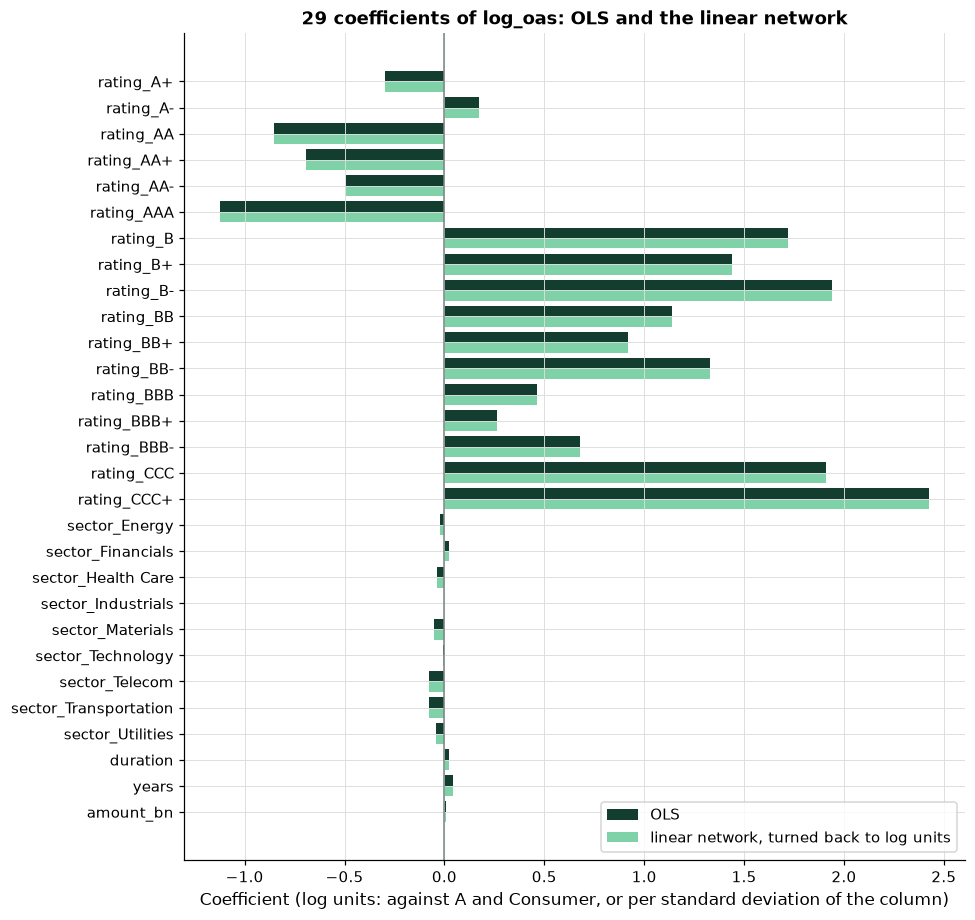

In [18]:
# every coefficient but the intercept, OLS and the network side by side; the prefixes are cut for the labels
slopes = pd.DataFrame({"OLS": ols_coef.drop("intercept"), "network": net_coef.drop("intercept")})
slopes.index = [name.split("__")[1] for name in slopes.index]
rows = np.arange(len(slopes))
fig, ax = plt.subplots(figsize=(9, 8.5))
ax.barh(rows - 0.2, slopes["OLS"], height=0.4, color=plotkit.GREEN_DARK, label="OLS")
ax.barh(rows + 0.2, slopes["network"], height=0.4, color=plotkit.GREEN_LIGHT, label="linear network, turned back to log units")
ax.set_yticks(rows, labels=slopes.index)
# the first coefficient at the top
ax.invert_yaxis()
ax.axvline(0, color=plotkit.GREY, linewidth=1)
ax.set_title(f"{len(slopes)} coefficients of log_oas: OLS and the linear network")
ax.set_xlabel("Coefficient (log units: against A and Consumer, or per standard deviation of the column)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

* Every pair is two bars of the same length: the network and OLS are one line. The rating dummies carry the fit, from AAA at -1.1236 to CCC+ at 2.4268 against A; the nine sector dummies and the three numbers all stay within 0.08 of 0.

## 6.2 Three Losses, and What Each Does to a Large Miss

The loss is the number fitting makes small. For a number rather than a class there are three common choices, each an average over the rows of a function of the residual e = actual - fitted:

* **MSE**, the mean squared error: the average of e squared. OLS minimises it. A miss twice as large costs four times as much.
* **MAE**, the mean absolute error: the average of |e|. A miss twice as large costs twice as much.
* **Huber**, with a threshold delta: 0.5 e squared while |e| is at most delta, then delta (|e| - 0.5 delta) beyond it. Squared for small misses, straight for large ones, and the two pieces join smoothly at delta. Keras's default delta is 1.0.

Q. Add `regression_losses` to `netkit.py`. Read the docstring first.

In [19]:
%%writefile -a netkit.py


from sklearn.model_selection import train_test_split  # a random fifth of a fold's training rows to stop on


def regression_losses(y_true, y_fitted, delta: float = 1.0) -> dict[str, float]:
    """Three regression losses by hand: mean squared error, mean absolute error, and the Huber loss.

    Inputs: y_true and y_fitted, the same length, in the target's unit; delta, where the Huber loss turns from
    squared to straight (in the target's unit, above 0).
    Output: {"mse", "mae", "huber"}. Huber is the mean of 0.5 e^2 where |e| <= delta and
    delta (|e| - 0.5 delta) elsewhere, so a large residual counts in proportion, not squared.
    Convention: equal to keras.losses.mean_squared_error, mean_absolute_error, and Huber(delta) within 1e-6.
    Excel: =SUMXMY2(a,b)/COUNT(a), =AVERAGE(ABS(a-b)), and =IF(ABS(e)<=d,0.5*e^2,d*(ABS(e)-0.5*d)) averaged.
    Raises ValueError on inputs that are empty or of different lengths, or delta not above 0.
    """
    actual = np.asarray(y_true, dtype=float).ravel()
    fitted = np.asarray(y_fitted, dtype=float).ravel()
    if actual.size == 0 or actual.size != fitted.size:
        raise ValueError(f"inputs must be non-empty and the same length, not {actual.size} and {fitted.size}")
    if not delta > 0:
        raise ValueError(f"delta must be above 0, not {delta}")
    error = actual - fitted
    size = np.abs(error)
    huber = np.where(size <= delta, 0.5 * error ** 2, delta * (size - 0.5 * delta))
    return {"mse": float(np.mean(error ** 2)), "mae": float(np.mean(size)), "huber": float(np.mean(huber))}

Appending to netkit.py


* The first line imports `train_test_split`, which `cv_regressor` uses later today; imports go at the top of the day's code.
* `np.where(size <= delta, ...)` picks the squared piece or the straight piece row by row: Excel's `IF`, filled down.
* The function refuses inputs of different lengths and a delta that is not above 0.

Q. Add the tests. The three helpers at the top build seeded rows and a small network for section 6.5's tests; the two tests below them are about the losses.

In [20]:
%%writefile -a test_netkit.py


def regression_frame(n: int = 150) -> tuple[pd.DataFrame, pd.Series]:
    """Seeded rows and a target near 5 with spread about 0.5, like a log spread in bp."""
    X, _ = small_frame(n)
    rng = np.random.default_rng(SEED)
    y = pd.Series(5.0 + 0.4 * X["a"] - 0.2 * X["b"] + rng.normal(scale=0.2, size=n), index=X.index)
    return X, y


def linear_build(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, name="output")], name="linear")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="mse")
    return model


@cache
def small_cv_regressor() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_regressor run on regression_frame, shared by the tests below: (table, out_of_fold, fitted rows)."""
    X, y = regression_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_regressor(linear_build, RecordingScaler(), X, y, epochs=5, batch_size=32, patience=2)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_regression_losses_match_keras():
    rng = np.random.default_rng(SEED)
    actual = rng.normal(size=40).astype("float32")
    fitted = (actual + rng.normal(scale=1.5, size=40)).astype("float32")
    losses = netkit.regression_losses(actual, fitted, delta=1.0)
    assert losses["mse"] == pytest.approx(float(keras.losses.mean_squared_error(actual, fitted)), abs=1e-6)
    assert losses["mae"] == pytest.approx(float(keras.losses.mean_absolute_error(actual, fitted)), abs=1e-6)
    assert losses["huber"] == pytest.approx(float(keras.losses.Huber(delta=1.0)(actual, fitted)), abs=1e-6)


def test_regression_losses_huber_switches_at_delta():
    # errors 0.5 (inside delta 1: 0.5 * 0.25 = 0.125) and 3 (outside: 1 * (3 - 0.5) = 2.5)
    losses = netkit.regression_losses([0.0, 0.0], [0.5, 3.0], delta=1.0)
    assert losses["huber"] == pytest.approx((0.125 + 2.5) / 2, abs=1e-12)
    assert losses["mse"] == pytest.approx((0.25 + 9.0) / 2, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.regression_losses([0.0], [0.5], delta=0.0)

Appending to test_netkit.py


* `test_regression_losses_match_keras` compares all three losses with Keras's own, within 1e-6 (Keras works in float32). `test_regression_losses_huber_switches_at_delta` works two residuals by hand: 0.5, inside delta 1, costs 0.5 x 0.25 = 0.125; 3, outside, costs 1 x (3 - 0.5) = 2.5.

Q. Reload `netkit` and run the tests.

In [21]:
# the file changed, so reload before using the new function
importlib.reload(netkit)
print(f"regression_losses in netkit: {hasattr(netkit, 'regression_losses')}")

regression_losses in netkit: True


In [22]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................                                               [100%]
26 passed in 13.91s



* `26 passed`: the 24 tests days 1 to 5 wrote, and today's first two.

Q. Compute the three losses of the linear network's fitted values, in log units, by `netkit` and by Keras.

In [23]:
# the network's fitted log spreads against the actual ones, delta 1.0 for Huber (Keras's default)
losses = netkit.regression_losses(y, fitted_log, delta=1.0)
for name, value in losses.items():
    print(f"{name}: {value:.4f}")

# Keras's own losses on the same numbers, in float32
actual_32, fitted_32 = y.to_numpy("float32"), fitted_log.astype("float32")
keras_losses = {"mse": float(keras.losses.mean_squared_error(actual_32, fitted_32)),
                "mae": float(keras.losses.mean_absolute_error(actual_32, fitted_32)),
                "huber": float(keras.losses.Huber(delta=1.0)(actual_32, fitted_32))}
print(f"equal to Keras's within 1e-6: {all(abs(losses[k] - keras_losses[k]) < 1e-6 for k in losses)}")

mse: 0.0620
mae: 0.1887
huber: 0.0306
equal to Keras's within 1e-6: True


* MSE 0.0620, MAE 0.1887, Huber 0.0306, all in log units (MSE in log units squared). The three are on different scales, so they are never compared with each other directly; each is compared with itself across models.

Q. Which bonds does the line miss by most, and how much of each loss do the six largest misses make up?

In [24]:
# residuals in log units: the part of each log spread the model misses
residual = y - fitted_log
size = residual.abs()
huber_rows = np.where(size <= 1.0, 0.5 * residual ** 2, 1.0 * (size - 0.5))
largest = size.sort_values(ascending=False).index[:6]

six = pd.DataFrame({"rating": train.loc[largest, "rating"], "oas_bp": train.loc[largest, "oas"],
                    "fitted_bp": np.exp(fitted_log[[y.index.get_loc(i) for i in largest]]),
                    "residual": residual[largest], "squared": residual[largest] ** 2, "absolute": size[largest],
                    "huber": pd.Series(huber_rows, index=y.index)[largest]})
six.index.name = "bond (row)"

# each loss is an average, so a row's share of the total is its share of the loss
print(f"share of the total from these six of {len(y)} bonds: "
      f"squared {(residual[largest] ** 2).sum() / (residual ** 2).sum():.1%}, "
      f"absolute {size[largest].sum() / size.sum():.1%}, "
      f"Huber {pd.Series(huber_rows, index=y.index)[largest].sum() / huber_rows.sum():.1%}")
print(f"residuals beyond delta = 1.0: {(size > 1.0).sum()}")

# the six bonds: spreads in bp, the residual and each loss's charge in log units; nothing is marked (rows are bonds)
plotkit.styled(six, [], "The linear network's six largest misses on the 615 bonds it was fitted on: spreads in bp, residual and each loss's charge in log units")

share of the total from these six of 615 bonds: squared 18.3%, absolute 5.3%, Huber 17.3%
residuals beyond delta = 1.0: 3


,rating,oas_bp,fitted_bp,residual,squared,absolute,huber
bond (row),,,,,,,
386,B,"2,074",414.094,1.611,2.596,1.611,1.111
47,B,"1,446",426.600,1.221,1.490,1.221,0.721
789,B-,"1,718",524.675,1.186,1.407,1.186,0.686
533,B,933,423.436,0.790,0.624,0.790,0.312
365,CCC+,"1,551",802.408,0.659,0.434,0.659,0.217
320,A-,174,91.689,0.641,0.410,0.641,0.205


* The largest miss is a B bond at 2,074 bp, 1.611 in log units above the line. Squared, that one bond costs 2.596; in the Huber loss, beyond delta, it costs 1.111, its straight part.
* The table's last three columns are what each loss charges these six bonds. Six bonds of 615 make up 18.3 percent of the squared error, 17.3 percent of the Huber loss, and 5.3 percent of the absolute error. **The MSE leans hardest on the largest misses**, so a model fitted with it bends toward them; the MAE leans least; Huber sits between, and only 3 residuals here are beyond its delta.
* Course 4 day 4 found that the generator multiplied six bonds' spreads by 2.5 to 4, which adds 0.92 to 1.39 to a log spread, and that no column in the file says which bonds those were. Residuals of that size are what such bonds leave behind. Every bond stays in: dropping the hardest bonds would choose the data to suit the model.

Q. Draw what each loss charges one bond for a miss, with the six largest misses marked, and each loss's share from those six.

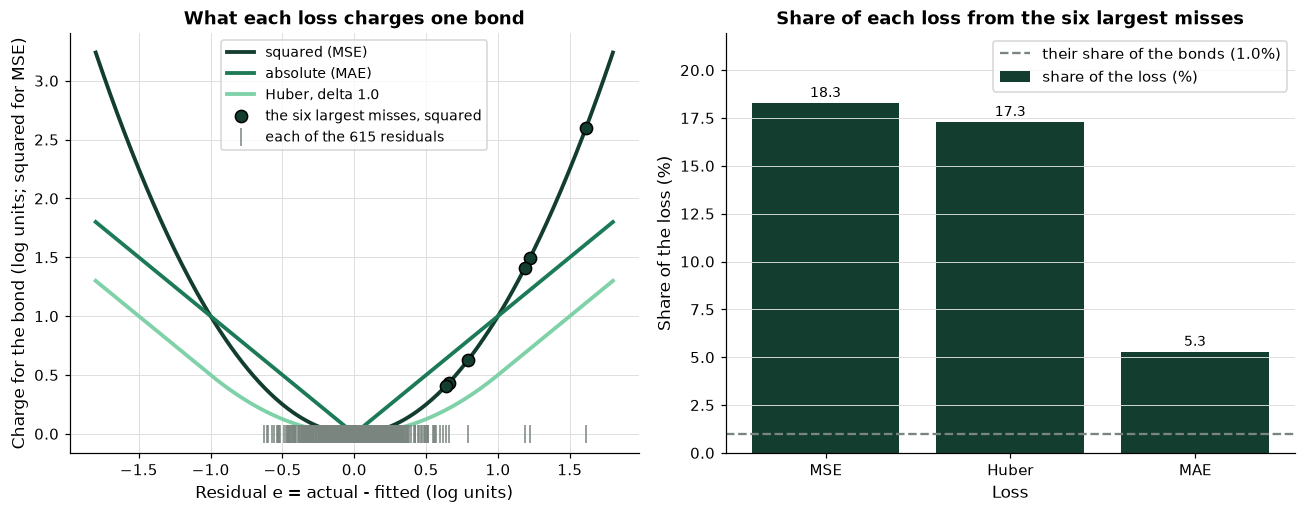

In [25]:
# each loss's charge for one bond as a function of its residual e, in log units, delta 1.0
e = np.linspace(-1.8, 1.8, 361)
charge = {"squared (MSE)": e ** 2, "absolute (MAE)": np.abs(e),
          "Huber, delta 1.0": np.where(np.abs(e) <= 1.0, 0.5 * e ** 2, 1.0 * (np.abs(e) - 0.5))}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8))
for (name, values), colour in zip(charge.items(), [plotkit.GREEN_DARK, plotkit.GREEN, plotkit.GREEN_LIGHT]):
    left.plot(e, values, color=colour, linewidth=2.5, label=name)
# the six largest misses on the squared curve, and every bond's residual as a tick along the bottom
left.plot(residual[largest], residual[largest] ** 2, "o", color=plotkit.GREEN_DARK, markersize=8, markeredgecolor="black",
          label="the six largest misses, squared")
left.plot(residual, np.zeros(len(residual)), "|", color=plotkit.GREY, markersize=12, label=f"each of the {len(y)} residuals")
left.set_title("What each loss charges one bond")
left.set_xlabel("Residual e = actual - fitted (log units)")
left.set_ylabel("Charge for the bond (log units; squared for MSE)")
left.legend(fontsize=9)

# each loss's share from the six bonds, against their share of the bonds
shares = pd.DataFrame({"share of the loss (%)": [100 * (residual[largest] ** 2).sum() / (residual ** 2).sum(),
                                                 100 * pd.Series(huber_rows, index=y.index)[largest].sum() / huber_rows.sum(),
                                                 100 * size[largest].sum() / size.sum()]},
                      index=pd.Index(["MSE", "Huber", "MAE"], name="Loss"))
plotkit.bars(shares, "Share of each loss from the six largest misses", "Share of the loss (%)", ax=right, fmt="{:.1f}")
right.axhline(100 * 6 / len(y), color=plotkit.GREY, linestyle="--", label=f"their share of the bonds ({600 / len(y):.1f}%)")
right.set_ylim(0, 1.2 * shares.to_numpy().max())
right.legend()
fig.tight_layout()
plt.show()

* Left: up to a residual of about 1 the three curves stay close; beyond it the squared curve climbs away. The largest miss, 1.611, costs 2.596 squared, 1.611 absolute, and 1.111 in the Huber loss. The grey ticks show how few bonds sit out there.
* Right: six bonds, 1.0 percent of the 615 (the dashed line), make up 18.3 percent of the squared error, 17.3 percent of the Huber loss, and 5.3 percent of the absolute error.

## 6.3 Standardizing the Target, and Turning It Back

Section 6.1 fitted the target in standard units. Why? A fresh `Dense` layer starts with small weights and an intercept of 0, so its first outputs are near 0. The log spreads average 4.88, so on the raw target every first output misses by about 5, and the first steps go into walking the intercept up from 0 rather than into the weights. In standard units the target averages 0 with a standard deviation of 1, where a fresh layer's outputs already are.

Q. Fit the same network with the same settings on the raw `log_oas`. How far from OLS is it after 300 epochs?

In [26]:
# the same network, the same seed, the same 300 full-batch epochs; the only change is the target
keras.utils.set_random_seed(SEED)
raw = keras.Sequential([keras.Input(shape=(A_all.shape[1],)), keras.layers.Dense(1, name="output")],
                       name="linear_regression")
raw.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss="mse")
raw_history = raw.fit(A_all, y.to_numpy("float32"), epochs=300, batch_size=len(A_all), shuffle=False, verbose=0)

# on the raw target the weights are already in log units
raw_kernel, raw_bias = raw.get_weights()
raw_coef = pd.Series(np.r_[raw_bias[0], raw_kernel.ravel()], index=ols_coef.index)
raw_fitted = raw.predict(A_all, verbose=0).ravel()
print(f"raw target: loss epoch 1 {raw_history.history['loss'][0]:.4f}, epoch 300 {raw_history.history['loss'][-1]:.6f}")
print(f"largest coefficient gap from OLS: raw target {(raw_coef - ols_coef).abs().max():.4f}, "
      f"standardized target below 1e-4: {(net_coef - ols_coef).abs().max() < 1e-4}")
print(f"largest fitted-spread gap from OLS: {np.abs(np.exp(raw_fitted) - np.exp(ols_fitted)).max():.2f} bp")

raw target: loss epoch 1 24.8203, epoch 300 0.122785
largest coefficient gap from OLS: raw target 1.2767, standardized target below 1e-4: True
largest fitted-spread gap from OLS: 236.52 bp


Q. Draw both runs' loss by epoch in the same units, beside OLS's mean squared error.

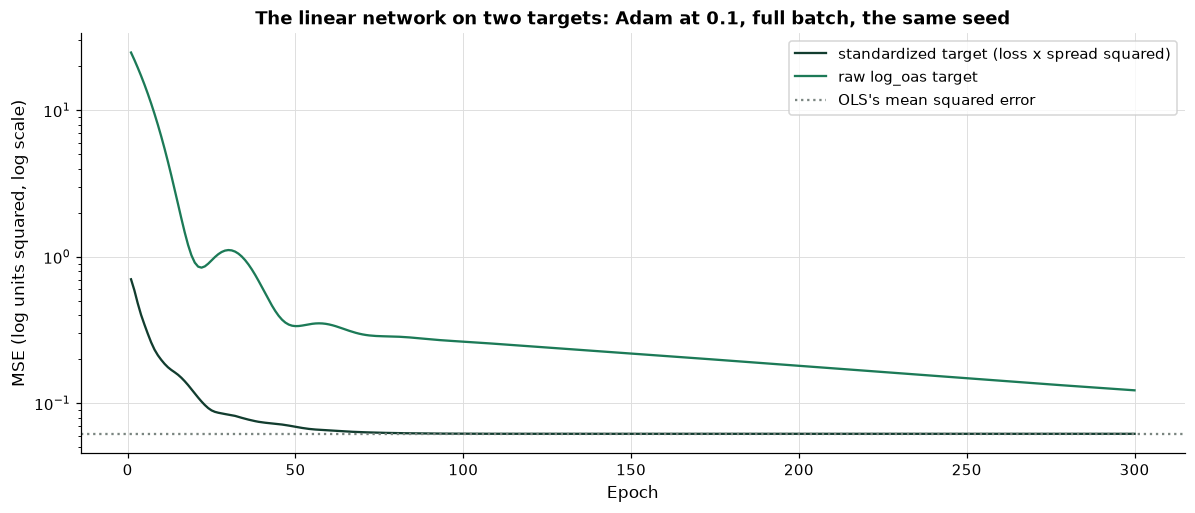

In [27]:
# the standardized run's loss times spread squared is its mean squared error in log units, the raw run's units
by_epoch = pd.DataFrame({"standardized target (loss x spread squared)": np.array(lin_history.history["loss"]) * spread ** 2,
                         "raw log_oas target": raw_history.history["loss"]},
                        index=pd.RangeIndex(1, 300 + 1, name="Epoch"))
fig, ax = plt.subplots(figsize=(11, 4.8))
plotkit.line_compare(by_epoch, "The linear network on two targets: Adam at 0.1, full batch, the same seed",
                     "MSE (log units squared, log scale)", ax=ax)
ax.axhline(np.mean((y - ols_fitted) ** 2), color=plotkit.GREY, linestyle=":", label="OLS's mean squared error")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()

* In the same units, the standardized run is within 1 percent of OLS's mean squared error by epoch 82 and on it at epoch 300. The raw run starts at 24.82 and at epoch 300 is still falling, at 0.1228, about twice OLS's 0.0620.

* On the raw target the first epoch's loss is 24.82, against 1.2214 in standard units: the outputs start about 5 away from every target. After the same 300 epochs the raw-target network is still 0.0604 above OLS's mean squared error, its largest coefficient is 1.2767 away from OLS's, and one bond's fitted spread is 236.52 bp from OLS's. It would get there with more epochs; standardizing gets there in these. One setting changed from the network of section 6.1: the target, standard units to raw log units; compared on the fit to the same 615 bonds.
* Standardizing the inputs (the encoder's `StandardScaler`) and the target are the same idea: give the network numbers of about the size its starting weights expect.

**Turning it back.** A network fitted on standard units gives standard units. Before anything is reported, the output is turned back: fitted log_oas = output x spread + centre, with the same centre and spread the target was standardized with. Then `exp` gives bp.

Q. Check that the turned-back fitted values carry the same fit: the mean squared error in log units is the standard-units MSE times spread squared.

In [28]:
# the network's raw output, in standard units, and the same output turned back to log units (both in float64)
output_std = linear.predict(A_all, verbose=0).ravel().astype("float64")
t_64 = ((y - centre) / spread).to_numpy()
mse_std = np.mean((t_64 - output_std) ** 2)
mse_log = np.mean((y - (output_std * spread + centre)) ** 2)
print(f"MSE in standard units {mse_std:.6f}; times spread squared {mse_std * spread ** 2:.6f}; in log units {mse_log:.6f}")
print(f"the two equal within 1e-9: {abs(mse_std * spread ** 2 - mse_log) < 1e-9}")

MSE in standard units 0.107640; times spread squared 0.061982; in log units 0.061982
the two equal within 1e-9: True


* Turning back is a straight-line change of units, so the fit is the same fit; only the units differ. In section 6.5 `cv_regressor` standardizes the target with each fold's **fit rows** only (their mean and standard deviation), so the held-out bonds never inform the scale, and it turns every fitted value back before it returns anything. The AI check is what happens when that last step is skipped.

## 6.4 The Learning Rate, from Too Small to Too Large

Day 1 took gradient steps by hand on one neuron and saw a learning rate that was too large. Now the same question on a network with hidden layers, fitted by **plain gradient descent on mini-batches** (`keras.optimizers.SGD`, batch 32): each step moves every weight by the learning rate times its gradient. One fold is enough to see it: fold 1 of `mlkit.cv_folds("regression")`, its 492 training bonds split as `cv_regressor` splits them, a random fifth to stop on.

Q. Take fold 1's training bonds, split off the stopping rows, and scale both on the fit rows only.

In [29]:
from sklearn.model_selection import train_test_split

# fold 1 of the course's five regression folds; its held-out bonds are not used in this section
folds = list(mlkit.cv_folds("regression").split(X, y))
train_1, held_1 = folds[0]
# a random fifth of the fold's training bonds to stop on, as cv_regressor does
X_fit, X_stop, y_fit, y_stop = train_test_split(X.iloc[train_1], y.iloc[train_1], test_size=0.2, random_state=SEED)
mlkit.assert_disjoint(X_fit.index, X_stop.index)

# the encoder fitted on the fit rows only; the stopping and held-out rows are transformed with that copy
_, A_fit, A_stop, A_held = netkit.fit_arrays(encoder, X_fit, X_stop, X.iloc[held_1])
# the target in standard units of the fit rows
centre_fit, spread_fit = y_fit.mean(), y_fit.std(ddof=0)
t_fit = ((y_fit - centre_fit) / spread_fit).to_numpy("float32")
t_stop = ((y_stop - centre_fit) / spread_fit).to_numpy("float32")
print(f"fold 1: {len(train_1)} training bonds, {len(X_fit)} to fit and {len(X_stop)} to stop on; {len(held_1)} held out")

fold 1: 492 training bonds, 393 to fit and 99 to stop on; 123 held out


Q. Fit a network of 16 and 8 ReLU units with plain SGD at four learning rates, 0.0003, 0.03, 0.3, 1, for 60 epochs each, and record the loss on the fit rows and on the stopping rows after every epoch.

In [30]:
def build_sgd(learning_rate):
    """16 and 8 ReLU units, a linear output, plain SGD at the given learning rate, the MSE loss."""
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(A_fit.shape[1],)),
                              keras.layers.Dense(16, activation="relu", name="hidden_1"),
                              keras.layers.Dense(8, activation="relu", name="hidden_2"),
                              keras.layers.Dense(1, name="output")], name="network_16_8")
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=learning_rate), loss="mse")
    return model


sgd_nets, curves = {}, {}
for rate in [0.0003, 0.03, 0.3, 1.0]:
    model = build_sgd(rate)
    # validation_data records the stopping rows' loss after each epoch; nothing stops early here
    history = model.fit(A_fit, t_fit, validation_data=(A_stop, t_stop), epochs=60, batch_size=32, verbose=0)
    sgd_nets[rate] = model
    curves[rate] = netkit.history_table(history)

sgd_table = pd.DataFrame({rate: {"fit loss, epoch 1": c["loss"].iloc[0], "fit loss, epoch 60": c["loss"].iloc[-1],
                                 "stopping loss, epoch 60": c["val_loss"].iloc[-1],
                                 "lowest stopping loss": c["val_loss"].min(),
                                 "at epoch": c["val_loss"].idxmin()} for rate, c in curves.items()}).T
sgd_table["at epoch"] = sgd_table["at epoch"].astype(int)
sgd_table.index.name = "learning rate"
# lower is better in the three loss columns after epoch 1; each marks its own lowest value
plotkit.styled(sgd_table, ["fit loss, epoch 60", "stopping loss, epoch 60", "lowest stopping loss"],
               "Plain SGD at four learning rates, 16 and 8 ReLU units, batch 32: MSE in standard units on fold 1's 393 fit rows and 99 stopping rows",
               higher_is_better=False, fmt="{:.4f}")

,"fit loss, epoch 1","fit loss, epoch 60","stopping loss, epoch 60",lowest stopping loss,at epoch
learning rate,,,,,
0.0003,0.9849,0.9527,1.0754,1.0754,60
0.03,0.9707,0.0777,0.1287,0.1287,60
0.3,0.9504,0.0620,0.1557,0.1296,24
1,44.7752,115.8892,111.0100,111.0100,2


* **Too small (0.0003).** The fit loss goes from 0.9849 to 0.9527 in 60 epochs: in standard units a loss of 1 is what the mean alone gives, so the network has barely started. Nothing is wrong with it except that it would need hundreds of times more steps.
* **About right (0.03).** The fit loss falls to 0.0777 and the stopping loss to 0.1287, still falling at epoch 60.
* **Fast (0.3).** The fit loss gets lowest of all, 0.0620, but the stopping loss is lowest at epoch 24 (0.1296) and is 0.1557 by epoch 60: the network is fitting the fit rows' noise. That is what early stopping is for (day 4), and `cv_regressor` uses it.
* **Too large (1).** The fit loss averages 44.7752 over the first epoch, against 1 for a network that gives every fit bond the mean, and 115.8892 after 60: each step overshoots, and the loss grows instead of falling. Here it stays a finite number; it is still a network that fitted nothing.
* The marks: 0.3 has the lowest fit loss at epoch 60, and 0.03 both stopping columns.
* One setting changed between the four runs: the learning rate; compared on the 99 stopping rows of fold 1.

Q. Draw the curves: the fit rows' loss and the stopping rows' loss by epoch, one line per learning rate, with each lowest stopping loss marked.

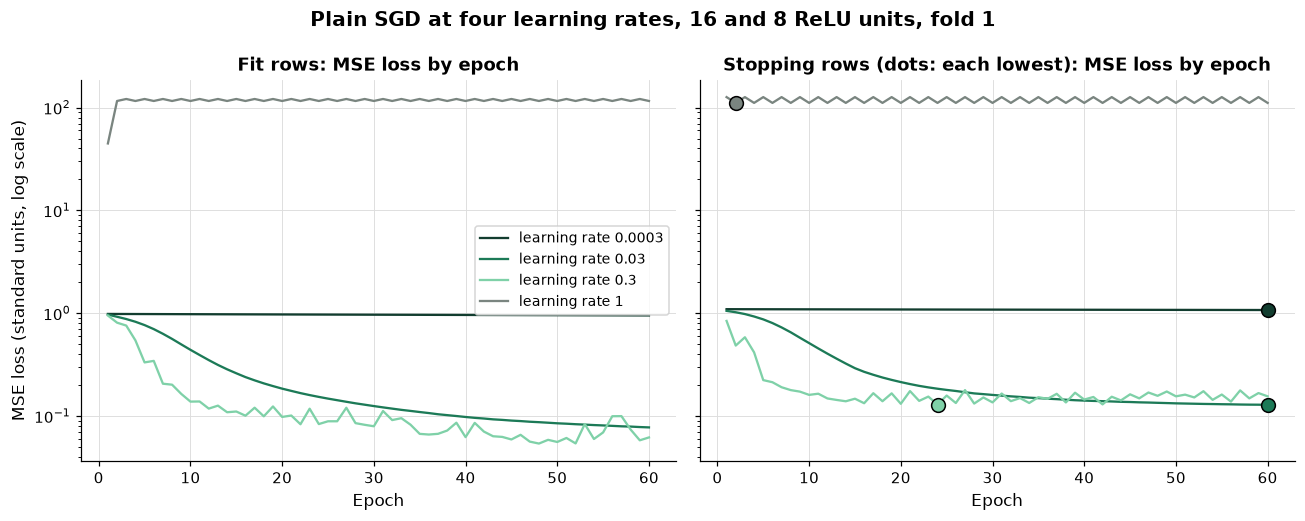

In [31]:
# plt was imported in the setup, with the course's chart style
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for rate, c in curves.items():
    left.plot(c.index, c["loss"], label=f"learning rate {rate:g}")
    line, = right.plot(c.index, c["val_loss"], label=f"learning rate {rate:g}")
    # each rate's lowest stopping loss: a dot in its line's colour
    right.plot(c["val_loss"].idxmin(), c["val_loss"].min(), "o", color=line.get_color(), markersize=9, markeredgecolor="black")
for axis, title in [(left, "Fit rows"), (right, "Stopping rows (dots: each lowest)")]:
    # a log scale, so a loss of 100 and a loss of 0.1 fit on one chart
    axis.set_yscale("log")
    axis.set_title(f"{title}: MSE loss by epoch")
    axis.set_xlabel("Epoch")
left.set_ylabel("MSE loss (standard units, log scale)")
# the legend where no line runs: between learning rate 1 near 100 and the rest near 1
left.legend(fontsize=9, loc="center right")
fig.suptitle("Plain SGD at four learning rates, 16 and 8 ReLU units, fold 1", fontweight="bold")
plt.tight_layout()
plt.show()

* The dots: 0.3's lowest stopping loss, at epoch 24, sits just above 0.03's at epoch 60 (0.1296 against 0.1287); 1's is at epoch 2, far above the rest.
* On a log scale the four stories separate. 0.0003 is a nearly flat line near 1. 0.03 falls steadily on both sides. 0.3 falls fastest on the fit rows, while its stopping curve bottoms out and turns up. 1 sits far above the rest on both. Week 2's next days are about choosing this setting well: day 7 gives Adam, which scales each weight's step for you, and learning-rate schedules.

## 6.5 Five Folds: Three Networks Beside OLS

Section 6.4 fitted on one fold and scored nothing. To score a network on these bonds, every bond needs a fitted value from a network that never saw it: five folds, each fold's network fitted on the other four with its own stopping rows, its own encoder, and its own target scale. `cv_regressor` writes that loop down once.

Q. Add `cv_regressor` to `netkit.py`.

In [32]:
%%writefile -a netkit.py


def cv_regressor(build, transformer, X, y, cv=None, epochs: int = 100, batch_size: int = 32,
                 patience: int = 10) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a regression network: out-of-fold fitted values, in the target's own units.

    Inputs: build, a function build(n_inputs) that returns a compiled model with a linear output; transformer, an
    unfitted scaler or ColumnTransformer (fit_arrays fits a fresh clone per fold); X, y, the training rows (a
    DataFrame and a Series, for example log_oas); cv, the splitter (default mlkit.cv_folds("regression")); epochs,
    batch_size, patience as cv_network.
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with mae and r2 on the held-out fold in
    the target's units (mlkit.regression_metrics) and best_epoch; out_of_fold holds each row's fitted value from
    the network that did not see it, in the order of X and in the target's units.
    Convention: per fold, a random fifth of the fold's training rows (seed 42) are the stopping rows; the target is
    standardized with the fit rows' mean and standard deviation (ddof=0) for fitting and turned back before anything
    is returned. For a log_oas target, ensemblekit.mae_bp(y, out_of_fold) gives the error in bp.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds("regression")
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        # the target in standard units of the fit rows, so the network's output layer starts near the right scale
        centre, spread = float(y_fit.mean()), float(y_fit.std(ddof=0))
        t_fit = ((y_fit.to_numpy(float) - centre) / spread).astype("float32")
        t_stop = ((y_stop.to_numpy(float) - centre) / spread).astype("float32")
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, t_fit, validation_data=(A_stop, t_stop), epochs=epochs, batch_size=batch_size,
                            callbacks=[stop], verbose=0)
        # turned back to the target's units before anything is scored or returned
        fitted = model.predict(A_held, verbose=0).ravel().astype(float) * spread + centre
        out_of_fold[held_out] = fitted
        metrics = mlkit.regression_metrics(y_held, fitted)
        rows[f"fold_{number}"] = {"mae": metrics["mae"], "r2": metrics["r2"], "best_epoch": best_epoch(history)}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold

Appending to netkit.py


* For each fold: a random fifth of the fold's training rows to stop on (`train_test_split`, seed 42); `mlkit.assert_disjoint` that neither the fit nor the stopping rows touch the held-out fold; `fit_arrays` so the encoder sees the fit rows only; the target standardized with the fit rows' mean and standard deviation; the seed set, so each fold's network starts the same way whatever ran before; early stopping on the stopping rows; and the held-out fitted values **turned back** (`* spread + centre`) before they are scored or stored.
* It returns one row per fold (`mae`, `r2` in the target's units, and `best_epoch`) and the out-of-fold fitted values in the order of `X`. For a `log_oas` target, `ensemblekit.mae_bp(y, out_of_fold)` is the error in bp.

Q. Add the two tests.

In [33]:
%%writefile -a test_netkit.py


def test_cv_regressor_target_turned_back():
    X, y = regression_frame()
    table, out_of_fold, _ = small_cv_regressor()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    # fitted values are in the target's units (near 5), not in standard units (near 0)
    assert abs(out_of_fold.mean() - y.mean()) < y.std()
    for (_, test), mae in zip(mlkit.cv_folds("regression").split(X, y), table["mae"]):
        assert np.mean(np.abs(y.iloc[test] - out_of_fold[test])) == pytest.approx(mae, abs=1e-12)


def test_cv_regressor_held_out_never_fitted():
    X, y = regression_frame()
    _, _, fitted_on = small_cv_regressor()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds("regression").split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        assert len(fitted) == 96

Appending to test_netkit.py


* `test_cv_regressor_target_turned_back` checks that the fitted values sit near the target's mean (about 5, the units of the target), not near 0 (standard units), and that each fold's `mae` is the held-out bonds' own MAE. `test_cv_regressor_held_out_never_fitted` uses `RecordingScaler` from day 5, which writes down every set of rows it is fitted on: five fits, none touching its held-out fold, each on 96 rows (four fifths of four fifths of 150).

Q. Reload and run all of today's tests.

In [34]:
importlib.reload(netkit)
print(f"cv_regressor in netkit: {hasattr(netkit, 'cv_regressor')}")

cv_regressor in netkit: True


In [35]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................                                             [100%]
28 passed in 18.31s



* `28 passed`.

Q. First the bar: OLS's MAE in bp by the same five folds.

In [36]:
from sklearn.model_selection import cross_val_predict

# OLS's out-of-fold fitted log spreads: each bond's from the OLS fitted on the other four folds
oof_ols = cross_val_predict(Pipeline([("encode", encoder), ("model", LinearRegression())]), X, y,
                            cv=mlkit.cv_folds("regression"), n_jobs=1)
print(f"OLS by five folds: MAE {ensemblekit.mae_bp(y, oof_ols):.2f} bp")

OLS by five folds: MAE 41.72 bp


* 41.72 bp, Course 5's number for OLS without coupon. Every fitted value is the model's spread for a bond with these characteristics, from a model that did not see that bond.

Q. Score three networks of 16 and 8 ReLU units with `cv_regressor`, the same in every way except the loss: MSE, MAE, and Huber. Adam at 0.01, batch 32, up to 100 epochs, early stopping with patience 10 (the function's defaults).

In [37]:
def network_builder(loss):
    """A function build(n_inputs) for cv_regressor: 16 and 8 ReLU units, a linear output, Adam at 0.01, the given loss."""
    def build(n_inputs):
        keras.utils.set_random_seed(SEED)
        model = keras.Sequential([keras.Input(shape=(n_inputs,)),
                                  keras.layers.Dense(16, activation="relu", name="hidden_1"),
                                  keras.layers.Dense(8, activation="relu", name="hidden_2"),
                                  keras.layers.Dense(1, name="output")], name="network_16_8")
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss=loss)
        return model
    return build


cv = {}
for loss in ["mse", "mae", "huber"]:
    table, out_of_fold = netkit.cv_regressor(network_builder(loss), encoder, X, y)
    cv[loss] = (table, out_of_fold)
    print(f"network, {loss} loss: MAE {ensemblekit.mae_bp(y, out_of_fold):.2f} bp; best epochs {table['best_epoch'].tolist()}")

network, mse loss: MAE 41.08 bp; best epochs [34, 12, 14, 13, 31]


network, mae loss: MAE 40.45 bp; best epochs [24, 20, 12, 16, 49]


network, huber loss: MAE 42.71 bp; best epochs [30, 13, 17, 13, 7]


* Each line is five networks, one per fold, each stopped where its own stopping rows' loss was lowest: the best epochs run from 7 to 49, so early stopping, not the 100-epoch limit, decided the length of every fit.
* The loss each network was fitted with is also the loss its stopping rows were watched with: the MAE network stopped where its stopping rows' MAE was lowest.

Q. Put the four side by side: MAE in bp, its standard deviation across the folds, R-squared on log_oas, and the number of folds where each network's MAE is below OLS's.

In [38]:
def fold_mae_bp(fitted):
    """MAE in bp on each fold's held-out bonds."""
    return pd.Series([ensemblekit.mae_bp(y.iloc[h], fitted[h]) for _, h in folds], index=[f"fold_{k}" for k in range(1, 6)])


def fold_r2(fitted):
    """R-squared on log_oas, averaged over the five held-out folds."""
    return np.mean([mlkit.regression_metrics(y.iloc[h], fitted[h])["r2"] for _, h in folds])


fold_mae = pd.DataFrame({"ols": fold_mae_bp(oof_ols), **{f"network_{k}": fold_mae_bp(v[1]) for k, v in cv.items()}})
summary = pd.DataFrame({"mae_bp": fold_mae.mean(), "fold_sd_bp": fold_mae.std(ddof=0),
                        "r2": [fold_r2(oof_ols)] + [v[0]["r2"].mean() for v in cv.values()],
                        "folds_below_ols": [0] + [(fold_mae[c] < fold_mae["ols"]).sum() for c in fold_mae.columns[1:]]})
summary.index.name = "model"
# lower is better for the MAE, higher for R-squared; the fold standard deviation and the count are not marked
plotkit.styled(summary, ["mae_bp", "r2"], "OLS and three networks by the same five folds of the 615 training bonds: MAE in bp (mean and standard deviation over the folds), R-squared on log_oas",
               higher_is_better={"mae_bp": False, "r2": True}, fmt="{:.2f}").format("{:.4f}", subset=["r2"])

,mae_bp,fold_sd_bp,r2,folds_below_ols
model,,,,
ols,41.72,10.72,0.8794,0
network_mse,41.08,10.95,0.8659,3
network_mae,40.45,9.81,0.8720,3
network_huber,42.71,11.51,0.8647,1


* The MAE network misses by 40.45 bp, the MSE network by 41.08 bp, OLS by 41.72 bp, and the Huber network by 42.71 bp. The MAE network is 1.26 bp below OLS and below it in 3 of 5 folds; the MSE network is 0.64 bp below OLS (3 of 5 folds); the Huber network is 0.99 bp above it (1 of 5).
* The MAE loss scores best on an MAE metric, which is no surprise: it is fitted to the same kind of error it is scored on, and it leans least on the few largest misses (section 6.2). The Huber loss here, with delta 1 in standard units of the target, is squared for all but a handful of bonds, so it behaves much like MSE; why it lands above the MSE network on these folds, these five numbers cannot say.
* The fold standard deviations run from 9.81 to 11.51 bp, several times the largest gap between any two of the four models.
* The marks fall on two rows: the MAE network has the lowest MAE in bp, and OLS the highest R-squared (0.8794). R-squared scores squared errors of log_oas, the quantity OLS makes smallest; the MAE in bp scores absolute errors in bp.
* One setting changed between the three networks: the loss, MSE to MAE to Huber; scored by the same five folds inside the 615 training bonds.

Q. Draw each fold's MAE for the four models, and each model's mean with its fold standard deviation.

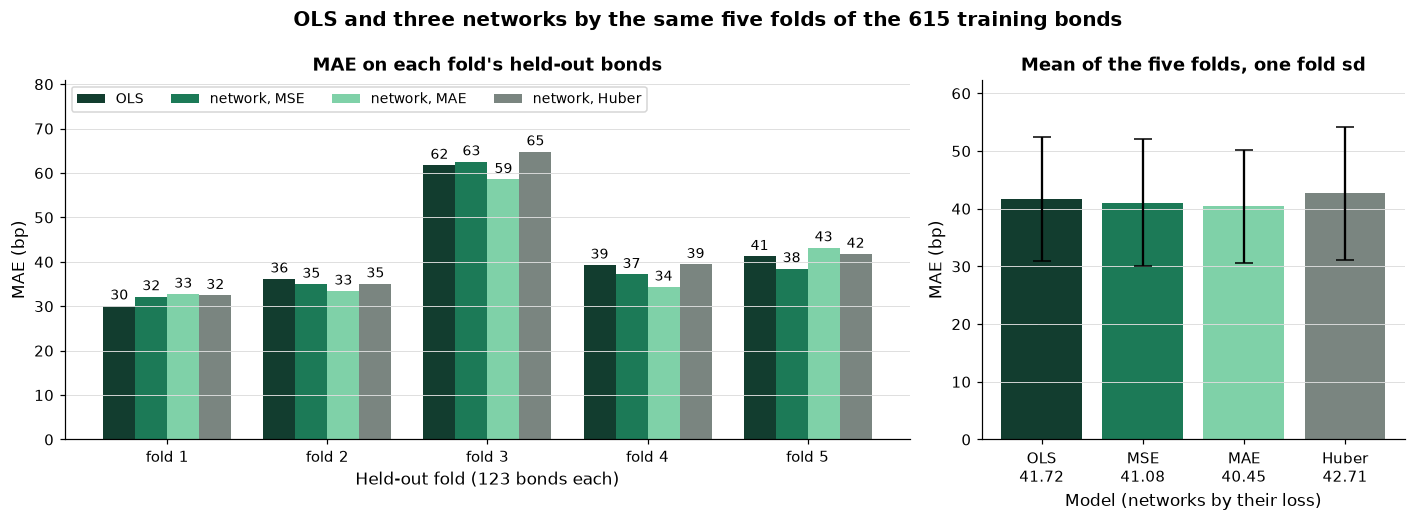

In [39]:
names = {"ols": "OLS", "network_mse": "network, MSE", "network_mae": "network, MAE", "network_huber": "network, Huber"}
short = {"ols": "OLS", "network_mse": "MSE", "network_mae": "MAE", "network_huber": "Huber"}
by_model = fold_mae.rename(columns=names)
by_model.index = pd.Index([f"fold {k}" for k in range(1, 6)], name="Held-out fold (123 bonds each)")
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2, 1]})
plotkit.bars(by_model, "MAE on each fold's held-out bonds", "MAE (bp)", ax=left, fmt="{:.0f}")
# headroom for the labels and the legend
left.set_ylim(0, 1.25 * by_model.to_numpy().max())
left.legend(ncol=4, fontsize=9, loc="upper left")

# each model's mean over the folds, the bar one fold standard deviation either way
positions = np.arange(len(summary))
right.bar(positions, summary["mae_bp"], yerr=summary["fold_sd_bp"], capsize=6,
          color=[plotkit.GREEN_DARK, plotkit.GREEN, plotkit.GREEN_LIGHT, plotkit.GREY])
right.set_xticks(positions, labels=[f"{short[m]}\n{v:.2f}" for m, v in summary["mae_bp"].items()])
right.set_xlabel("Model (networks by their loss)")
right.grid(axis="x", visible=False)
right.set_ylim(0, 1.15 * (summary["mae_bp"] + summary["fold_sd_bp"]).max())
right.set_title("Mean of the five folds, one fold sd")
right.set_ylabel("MAE (bp)")
fig.suptitle("OLS and three networks by the same five folds of the 615 training bonds", fontweight="bold")
fig.tight_layout()
plt.show()

* Left: the folds differ far more than the models do. Every model misses most on fold 3 (58.56 to 64.80 bp) and least on fold 1 (30.09 to 32.75 bp).
* Right: the four means lie within 2.25 bp of one another, and each error bar reaches 9.81 to 11.51 bp either side. In Excel, the fold table makes the same left-hand picture as a clustered column chart.

## 6.6 Does a Network Describe These Bonds Better than OLS?

Q. Compare OLS and the lowest network fold by fold.

In [40]:
# the same five sets of held-out bonds for both models
by_fold = fold_mae[["ols", "network_mae"]].assign(difference=fold_mae["network_mae"] - fold_mae["ols"])
print(f"folds where the network is below OLS: {(by_fold['difference'] < 0).sum()} of 5; "
      f"mean difference {by_fold['difference'].mean():.2f} bp")
# the rows are folds, not models, so nothing is marked
plotkit.styled(by_fold, [], "OLS and the MAE network on each fold's 123 held-out bonds: MAE in bp, and the network's minus OLS's",
               fmt="{:.2f}")

folds where the network is below OLS: 3 of 5; mean difference -1.26 bp


,ols,network_mae,difference
fold_1,30.09,32.75,2.66
fold_2,36.17,33.43,-2.74
fold_3,61.78,58.56,-3.22
fold_4,39.30,34.34,-4.96
fold_5,41.24,43.19,1.95


* Fold by fold the two move together: both miss most on fold 3 (61.78 bp for OLS) and least on fold 1 (30.09 bp), and the same is true of all four models: some folds simply hold harder bonds. The differences run from -4.96 to 2.66 bp; the network is below OLS in 3 of 5.
* **What the numbers support.** On these 615 bonds, the lowest network is 1.26 bp below OLS on average, a gap far smaller than the 10.72 bp the folds differ by. And these five folds both compared the three losses and report the winner, so its number is a little flattering: the lowest of three is lower than a fresh fold would give. The fair summary is that a network with two small hidden layers describes these bonds about as well as OLS, not clearly better.
* **Why so close.** Course 4 read the generator: it multiplies a rating level, a maturity term, an issuer effect, and noise, so in logs the parts add up, which is the shape of a linear model. A network's extra freedom has little to find in a recipe that is nearly a straight line in logs, and 615 bonds are few for a flexible model to learn a bend from. Neither the issuer effect nor the noise is in any column, so no model on these columns can describe them.

Q. Draw each model's out-of-fold fitted spreads against the actual spreads, and the residuals, in bp.

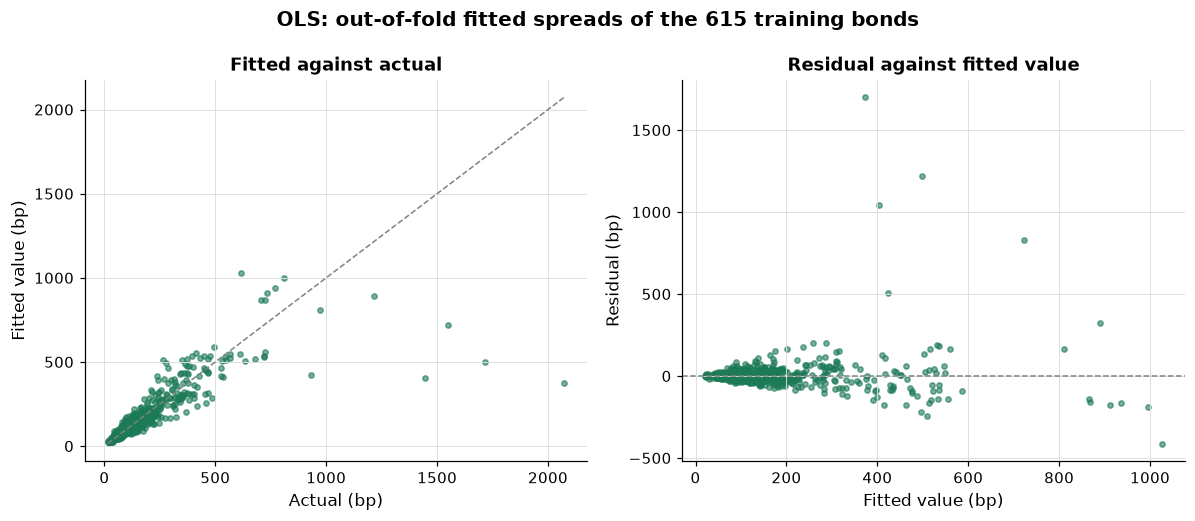

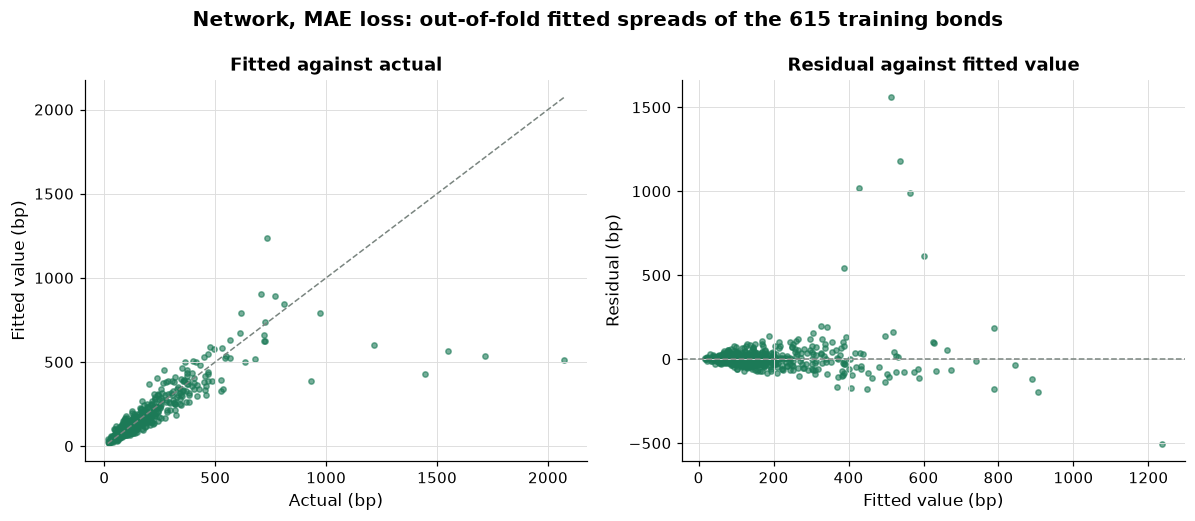

In [41]:
# each bond's fitted spread from the model fitted without its fold, turned from log units to bp with exp
for name, fitted in [("OLS", oof_ols), ("Network, MAE loss", cv["mae"][1])]:
    fig = plotkit.residual_plots(np.exp(y), np.exp(fitted), unit="bp")
    fig.suptitle(f"{name}: out-of-fold fitted spreads of the {len(y)} training bonds", fontweight="bold")
    fig.tight_layout()
    plt.show()

* The two pictures look alike, which is section 6.5's result drawn. Left in each: the points hug the 45-degree line at narrow spreads and scatter more as spreads widen; the bonds far to the right and well below the line are wide spreads no column explains (the high points of the right-hand panel), and the largest miss is the same B bond at 2,074 bp for both (1,700.95 bp for OLS, 1,560.58 bp for the network).
* Right in each: the residuals fan out as the fitted spread rises. On the half of the bonds with the wider fitted spreads the average miss is 68.29 bp for OLS and 64.89 bp for the network, against 15.23 and 16.10 bp on the narrower half. A miss in logs is a share of the spread, so the same share is more bp on a wider spread. 80.3 percent of the bonds are missed by 50 bp or less by OLS, 80.5 percent by the network.

## 6.7 Units: the MAE in bp

Every MAE in this notebook is quoted in bp, and getting there takes two turns: standard units back to log units (x spread + centre), then log units to bp (`exp`). Skip either and the number is still an MAE, in the wrong units.

Q. Compute the MAE of the linear network's fitted values from section 6.1 in all three units.

In [42]:
# one set of fitted values, three units
mae_std = np.mean(np.abs(t_64 - output_std))
mae_log = np.mean(np.abs(y - fitted_log))
print(f"MAE in standard units of log_oas: {mae_std:.4f}")
print(f"MAE in log units: {mae_log:.4f} (the standard-units MAE times spread {spread:.4f})")
print(f"MAE in bp after exp: {ensemblekit.mae_bp(y, fitted_log):.2f}")

MAE in standard units of log_oas: 0.2487
MAE in log units: 0.1887 (the standard-units MAE times spread 0.7588)
MAE in bp after exp: 39.35


* 0.2487, 0.1887, and 39.35 bp, for the same fitted values on the 615 bonds they were fitted on (not a score). Only the last one is in bp, and only it can be set beside a spread. An MAE of 0.19 in log units means a typical miss of about 21 percent of the spread, which is in bp only once `exp` has been applied bond by bond.
* `ensemblekit.mae_bp` takes log spreads, both of them, and does the `exp`. It cannot tell if what it is given is in standard units: give it standard units and it returns a number, labelled bp by whoever prints it.

## Excel Side by Side

Excel has no network training: no layers, no optimizer, no early stopping, and no loop over folds. What it does have is every loss and every change of units in this notebook, each a formula. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-06) on the 615 training bonds, with `log_oas` in column A of a sheet named `losses`, the linear network's fitted `log_oas` (section 6.1) in column B, and OLS's out-of-fold fitted `log_oas` (section 6.5) in column E. The Huber formula was also tested on eight hand rows with one large residual, where it gave 0.954531 against `regression_losses`' 0.954531.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Residual | `y - fitted_log` | `=A2-B2` in C2, filled down | |
| MSE | `regression_losses(...)["mse"]` | `=SUMXMY2(A2:A616,B2:B616)/COUNT(A2:A616)` | 0.061982 |
| MAE | `regression_losses(...)["mae"]` | `=AVERAGE(ABS(A2:A616-B2:B616))` | 0.188728 |
| Huber, one row (delta in H1) | the `np.where` line | `=IF(ABS(C2)<=$H$1,0.5*C2^2,$H$1*(ABS(C2)-0.5*$H$1))` in D2, filled down | |
| Huber | `regression_losses(...)["huber"]` | `=AVERAGE(D2:D616)` | 0.030620 |
| MAE in bp | `ensemblekit.mae_bp(y, oof_ols)` | `=AVERAGE(ABS(EXP(A2:A616)-EXP(E2:E616)))` | 41.72 |
| Mean of the target | `y.mean()` | `=AVERAGE(A2:A616)` in K1 | 4.877576 |
| Standard deviation, ddof=0 | `y.std(ddof=0)` | `=STDEV.P(A2:A616)` in K2 | 0.758833 |
| Standard units | `(y - centre) / spread` | `=(A2-$K$1)/$K$2`, filled down | |
| Turn back | `output * spread + centre` | `=N2*$K$2+$K$1`, filled down | column B, within 1e-12 |

**The losses are three formulas.** `SUMXMY2` adds up the squared differences of two ranges, so dividing by `COUNT` gives the MSE in one cell. `AVERAGE(ABS(A2:A616-B2:B616))` subtracts the two columns row by row inside the formula, as numpy subtracts two arrays. The Huber loss needs a helper column: the residual in C, then the `IF` that picks the squared or the straight piece in D, and `AVERAGE` of D. That `IF` is `np.where` in `regression_losses`.

**The MAE in bp** takes `EXP` of both columns inside the `AVERAGE`, which is `ensemblekit.mae_bp`, cell for cell: OLS's 41.72 bp from section 6.5.

**Standard units are `AVERAGE` and `STDEV.P`.** `STDEV.P` returned the same number as `std(ddof=0)`, the population standard deviation, which divides by n; pandas's default `std()` divides by n - 1, so `ddof=0` is written out. Paste the network's raw outputs in column N and `=N2*$K$2+$K$1` turns them back to log spreads: column B, the fitted values every loss above was computed on.

Q. Do Excel's numbers equal Python's?

In [43]:
# Excel's numbers, from the course's Excel check, beside Python's for the same bonds
excel = {"MSE (log units)": 0.061981899263861676,
         "MAE (log units)": 0.1887277252988971,
         "Huber, delta 1 (log units)": 0.030619524489246198,
         "OLS out-of-fold MAE (bp)": 41.71658355334412,
         "mean of log_oas": 4.8775756761243425,
         "standard deviation of log_oas": 0.7588325154853659}
python = {"MSE (log units)": losses["mse"],
          "MAE (log units)": losses["mae"],
          "Huber, delta 1 (log units)": losses["huber"],
          "OLS out-of-fold MAE (bp)": ensemblekit.mae_bp(y, oof_ols),
          "mean of log_oas": centre,
          "standard deviation of log_oas": spread}

side_by_side = pd.DataFrame({"Excel": excel, "Python": python})
side_by_side["within 1e-12"] = (side_by_side["Excel"] - side_by_side["Python"]).abs() < 1e-12
plotkit.styled(side_by_side, [], "Excel against Python on the 615 training bonds: losses in log units, OLS's out-of-fold MAE in bp, the target's centre and spread",
               fmt="{:.6f}")

,Excel,Python,within 1e-12
MSE (log units),0.061982,0.061982,True
MAE (log units),0.188728,0.188728,True
"Huber, delta 1 (log units)",0.030620,0.030620,True
OLS out-of-fold MAE (bp),41.716584,41.716584,True
mean of log_oas,4.877576,4.877576,True
standard deviation of log_oas,0.758833,0.758833,True


* Every number matches within 1e-12. Excel's standardized column and its turned-back column also matched Python's on all 615 bonds within 1e-12.

## Save the Day with Git

The morning's commit holds the files as day 5 left them. Commit today's change on top, then the experiment log.

Q. Commit today's two functions and their tests.

In [44]:
# M marks a tracked file that changed since the last commit
!git -C "{work}" status --short
!git -C "{work}" add netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Add regression_losses and cv_regressor to netkit, 28 tests"

 M netkit.py
 M test_netkit.py
?? benchmark.csv
?? plotkit.py
?? ratings.csv


* `??` marks the untracked files: the two data files and `plotkit.py`, which every setup writes fresh and `netkit` does not import. None of them is today's work, so none is committed.

Q. Write today's scores to `results.csv`, with Course 6's regression columns: model, features, rows, MAE in bp, and R-squared.

In [45]:
# one row per model, scored by the same five folds; rows "cv" says how it was scored
results = pd.DataFrame({"model": ["ols"] + [f"network_16_8_{k}" for k in cv],
                        "features": "rating_sector_duration_years_amount", "rows": "cv",
                        "mae_bp": summary["mae_bp"].to_numpy(), "r2": summary["r2"].to_numpy()})
# 4 decimals and LF line endings, so a later diff shows a real change and prints the same everywhere
results.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))

model,features,rows,mae_bp,r2
ols,rating_sector_duration_years_amount,cv,41.7166,0.8794
network_16_8_mse,rating_sector_duration_years_amount,cv,41.0759,0.8659
network_16_8_mae,rating_sector_duration_years_amount,cv,40.4533,0.8720
network_16_8_huber,rating_sector_duration_years_amount,cv,42.7051,0.8647



In [46]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Experiment log: cross-validated MAE in bp of OLS and three networks on the benchmark"
!git -C "{work}" log --oneline

47cc49f Experiment log: cross-validated MAE in bp of OLS and three networks on the benchmark
084c2bc Add regression_losses and cv_regressor to netkit, 28 tests
0af93bb Start of day 6: mlkit, ensemblekit, and netkit as day 5 left them, 24 tests


* Three commits: the start of the day, the code, the results. The regression log has its own five columns; week 1's classification log had nine. A file holds one kind of row.

Q. Today's Git step: what did the last commit that touched `netkit.py` change in it?

In [47]:
# -p shows the patch, -1 the last commit only, and -- netkit.py limits it to commits that touched that file
!git -C "{work}" log -p -1 -- netkit.py

commit 084c2bc5697a1b73d9200a46eaebab73a2d2d506
Author: Course Student <student@example.com>
Date:   Mon Oct 12 21:08:16 2026 -0400

    Add regression_losses and cv_regressor to netkit, 28 tests

diff --git a/netkit.py b/netkit.py
index 7dec7b1..01954dd 100644
--- a/netkit.py
+++ b/netkit.py
@@ -321,3 +321,74 @@ def cv_network(build, transformer, X, y, cv=None, epochs: int = 200, batch_size:
                                   "average_precision": average_precision_score(y_held, output),
                                   "best_epoch": best_epoch(history), "epochs_run": len(history.history["loss"])}
     return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold
+
+
+from sklearn.model_selection import train_test_split  # a random fifth of a fold's training rows to stop on
+
+
+def regression_losses(y_true, y_fitted, delta: float = 1.0) -> dict[str, float]:
+    """Three regression losses by hand: mean squared error, mean absolute error, and the Huber loss.
+
+    Inputs: y_true 

* `git log -p -1 -- netkit.py` skipped the results commit, which did not touch the module, and showed the code commit: its message, then the patch. Lines starting with `+` were added, and none was removed, because today only appended. The patch is exactly today's two functions and the import above them.
* In your own `my_bondmath` folder the same command answers "what did I change in the module last time?" without scrolling through every commit.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\my_bondmath"
& "$HOME\projects\python-fixed-income\.venv\Scripts\Activate.ps1"
```

**Step 2.** Paste the code of today's two `%%writefile -a netkit.py` cells (sections 6.2 and 6.5), without their first lines, at the end of `netkit.py`; do the same for the two `test_netkit.py` cells. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_netkit.py
```

The last line says `28 passed`.

**Step 4.** Read the change, commit it, and read it back with today's Git step.

```powershell
git diff --stat
git add netkit.py test_netkit.py
git commit -m "Add regression_losses and cv_regressor to netkit, 28 tests"
git log -p -1 -- netkit.py
```

netkit's tests read no data file, so nothing needs copying. To run today's notebook cells on your own machine, `benchmark.csv` and `ratings.csv` are in the course repo's `data` folder.

## You Can Now

* Show that a `Dense(1)` output with no activation, fitted with the mean squared error, is a linear regression.
* Compute MSE, MAE, and the Huber loss by hand with `regression_losses`, and say which leans hardest on the largest misses.
* Standardize a target with the fit rows' mean and standard deviation, and turn every fitted value back before reporting it.
* Recognise a learning rate that is too small, about right, fast enough to overfit, and too large, from the loss curves.
* Score a regression network by five folds with `cv_regressor`, beside OLS, in bp.
* Say what a fold-by-fold comparison supports, and what it does not.

Next, day 7: momentum, Adam, and learning-rate schedules, back on the card file.

## Exercises

The exercises use Course 4's 615 benchmark training bonds; the 206 test bonds stay closed, the bonds are synthetic, and every answer describes the course's generator. Replace each `...` with your own code, then run the check cell. Worked answers are in the solutions notebook in this folder.

Q. Run the next cell first. It loads the bonds, builds section 6.1's encoder, defines section 6.5's `network_builder`, recomputes OLS's out-of-fold fitted values, and defines `check`, a small function that marks your answers.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Course 4's 615 training bonds of the synthetic benchmark, and section 6.1's inputs and encoder
train = ensemblekit.course4_bench_rows(pd.read_csv("benchmark.csv"), pd.read_csv("ratings.csv"))
X, y = train[["rating", "sector", "duration", "years", "amount_bn"]], train["log_oas"]
encoder = ColumnTransformer([
    ("categories", OneHotEncoder(drop=["A", "Consumer"], handle_unknown="ignore", sparse_output=False), ["rating", "sector"]),
    ("numbers", StandardScaler(), ["duration", "years", "amount_bn"]),
])


def network_builder(loss):
    """A function build(n_inputs) for cv_regressor: 16 and 8 ReLU units, a linear output, Adam at 0.01, the given loss."""
    def build(n_inputs):
        keras.utils.set_random_seed(SEED)
        model = keras.Sequential([keras.Input(shape=(n_inputs,)),
                                  keras.layers.Dense(16, activation="relu", name="hidden_1"),
                                  keras.layers.Dense(8, activation="relu", name="hidden_2"),
                                  keras.layers.Dense(1, name="output")], name="network_16_8")
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss=loss)
        return model
    return build


# OLS's out-of-fold fitted log spreads (section 6.5)
oof_ols = cross_val_predict(Pipeline([("encode", encoder), ("model", LinearRegression())]), X, y,
                            cv=mlkit.cv_folds("regression"), n_jobs=1)


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Fit section 6.5's MSE network by `cv_regressor` on `oas` in bp instead of `log_oas`: `netkit.cv_regressor(network_builder("mse"), encoder, X, train["oas"])`. The fitted values come back in bp, so the MAE in bp is the mean of `abs(oas - fitted)`. Store it in **ex1_mae_bp**. Is it above or below the log model's 41.08 bp?

In [49]:
ex1_mae_bp = ...

In [50]:
check("Exercise 1 MAE in bp, target in bp", ex1_mae_bp, 48.313263809641676)

Exercise 1 MAE in bp, target in bp: not attempted yet


### Exercise 2

Q. Score the same network with the Huber loss at `delta=0.5` instead of Keras's default 1.0: pass `keras.losses.Huber(delta=0.5)` to `network_builder`. Store its MAE in bp, `ensemblekit.mae_bp(y, out_of_fold)`, in **ex2_mae_bp**. Section 6.5's Huber network, at delta 1.0, gave 42.71 bp, and the MAE network 40.45 bp.

In [51]:
ex2_mae_bp = ...

In [52]:
check("Exercise 2 MAE in bp, Huber delta 0.5", ex2_mae_bp, 39.674190216488896)

Exercise 2 MAE in bp, Huber delta 0.5: not attempted yet


### Exercise 3

Q. Add a function to your module. `bp_errors(log_true, log_fitted)` returns each bond's error in bp, `exp(log_true) - exp(log_fitted)`, as a numpy array, and refuses inputs that are empty or of different lengths with `ValueError`. Write the docstring first. Then add `test_bp_errors_hand`, which checks on two bonds (spreads 100 and 250 bp, fitted 120 and 200 bp) that the errors are -20 and 50, that their mean absolute value equals `mae_bp` (reach it as `netkit.ensemblekit.mae_bp`), and that inputs of different lengths raise. Run pytest, reload the module, and store the largest absolute error in bp of OLS's out-of-fold fitted values, `np.abs(netkit.bp_errors(y, oof_ols)).max()`, in **ex3_largest_bp**.

Write the function in the cell that starts with `%%writefile -a netkit.py` and the test in the one that starts with `%%writefile -a test_netkit.py`, and run each of those cells once.

In [53]:
%%writefile -a netkit.py


# Exercise 3: write bp_errors(log_true, log_fitted) below this line

Appending to netkit.py


In [54]:
%%writefile -a test_netkit.py


# Exercise 3: write test_bp_errors_hand() below this line

Appending to test_netkit.py


In [55]:
# run pytest, reload the module, then use your function
ex3_largest_bp = ...

In [56]:
check("Exercise 3 the largest error in bp", ex3_largest_bp, 1700.9468994517752)

Exercise 3 the largest error in bp: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a function that scores a network fitted on a standardized `log_oas` target, in bp, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The MAE in bp of a network fitted on a standardized log_oas target, on held-out bonds.

    Inputs: model, fitted on (log_oas - centre) / spread; A_held, the held-out bonds' scaled inputs; log_true,
    their log_oas; centre and spread, the fit rows' mean and standard deviation of log_oas.
    Output: the mean absolute error in bp, mean(|exp(log_true) - exp(fitted log_oas)|).
```

Q. Run the next cell first. It fits section 6.4's network at learning rate 0.03 on fold 1 again, with its fit rows' centre and spread, and keeps fold 1's 123 held-out bonds to score it on.

In [57]:
# fold 1, its stopping rows, and the encoder and target scale from its fit rows only (section 6.4)
folds = list(mlkit.cv_folds("regression").split(X, y))
train_1, held_1 = folds[0]
X_fit, X_stop, y_fit, y_stop = train_test_split(X.iloc[train_1], y.iloc[train_1], test_size=0.2, random_state=SEED)
_, A_fit, A_stop, A_held = netkit.fit_arrays(encoder, X_fit, X_stop, X.iloc[held_1])
y_held = y.iloc[held_1]
centre_fit, spread_fit = y_fit.mean(), y_fit.std(ddof=0)
t_fit = ((y_fit - centre_fit) / spread_fit).to_numpy("float32")
t_stop = ((y_stop - centre_fit) / spread_fit).to_numpy("float32")

# seed before building any Keras model, so its numbers never depend on what ran before
keras.utils.set_random_seed(SEED)
network_check = keras.Sequential([keras.Input(shape=(A_fit.shape[1],)),
                                  keras.layers.Dense(16, activation="relu", name="hidden_1"),
                                  keras.layers.Dense(8, activation="relu", name="hidden_2"),
                                  keras.layers.Dense(1, name="output")], name="network_16_8")
network_check.compile(optimizer=keras.optimizers.SGD(learning_rate=0.03), loss="mse")
network_check.fit(A_fit, t_fit, validation_data=(A_stop, t_stop), epochs=60, batch_size=32, verbose=0)
print(f"fitted on {len(X_fit)} bonds; {len(y_held)} held-out bonds to score")

fitted on 393 bonds; 123 held-out bonds to score


The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a number that looks like an error in bp, and contains one bug.

In [58]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def held_out_mae_bp(model, A_held, log_true, centre, spread):
    """The MAE in bp of a network fitted on a standardized log_oas target, on held-out bonds.

    Inputs: model, fitted on (log_oas - centre) / spread; A_held, the held-out bonds' scaled inputs; log_true,
    their log_oas; centre and spread, the fit rows' mean and standard deviation of log_oas.
    Output: the mean absolute error in bp, mean(|exp(log_true) - exp(fitted log_oas)|).
    """
    output = model.predict(A_held, verbose=0).ravel()
    # put the actual values on the network's scale, so both sides are in the same units
    actual = (np.asarray(log_true, dtype=float) - centre) / spread
    return ensemblekit.mae_bp(actual, output)

Q. Before you run the next cell: OLS misses fold 1's held-out bonds by 30.09 bp on average. What number do you expect for a network fitted on the same fold?

In [59]:
print(f"held_out_mae_bp on fold 1's held-out bonds: {held_out_mae_bp(network_check, A_held, y_held, centre_fit, spread_fit):.2f} bp")

held_out_mae_bp on fold 1's held-out bonds: 0.39 bp


Q. Test the function against its docstring before you trust it: its number must equal `mae_bp` on the network's output turned back to log units.

In [60]:
# the test, written from the docstring before the code is trusted
reported = held_out_mae_bp(network_check, A_held, y_held, centre_fit, spread_fit)
# the docstring's own formula: the output turned back to log units, then mae_bp on two log spreads
fitted_log_held = network_check.predict(A_held, verbose=0).ravel() * spread_fit + centre_fit
expected = ensemblekit.mae_bp(y_held, fitted_log_held)
assert abs(reported - expected) < 1e-9, f"reported {reported:.2f} bp; mae_bp on the turned-back fitted values {expected:.2f} bp"
print(f"held_out_mae_bp equal to mae_bp on the turned-back fitted values within 1e-9: {reported:.2f} bp")

AssertionError: reported 0.39 bp; mae_bp on the turned-back fitted values 33.28 bp

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's number, `held_out_mae_bp(network_check, A_held, y_held, centre_fit, spread_fit)`, in **ex4_mae_bp**.

In [61]:
# fix the function above and run the test again, then store the answer
ex4_mae_bp = ...

In [62]:
check("Exercise 4 the fixed MAE in bp", ex4_mae_bp, 33.28398737589368)

Exercise 4 the fixed MAE in bp: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```